# Analisis Keterlambatan Penerbangan AS 2015 dengan PySpark
Midterm Project Big Data & AI. Notebook dijalankan berurutan dan semua angka dihitung dari data di notebook ini.

**Tahap 1: Setup Spark dan ingestion.**

## 1. Konfigurasi Spark
Mode lokal, semua core, memori driver 4 GB, 16 partisi shuffle.

In [1]:
# Membuat SparkSession dengan konfigurasi tetap (dipakai seluruh notebook)
from pyspark.sql import SparkSession

spark = (SparkSession.builder
         .master("local[*]")
         .appName("flight_delays_2015")
         .config("spark.driver.memory", "4g")
         .config("spark.sql.shuffle.partitions", "16")
         .getOrCreate())

# Mengurangi log agar output notebook tidak penuh
spark.sparkContext.setLogLevel("WARN")

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/02 17:17:54 WARN Utils: Your hostname, macs-MacBook-Pro.local, resolves to a loopback address: 127.0.0.1; using 172.20.10.3 instead (on interface en0)
26/11/02 17:17:54 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/02 17:17:55 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


## 2. Versi lingkungan
Versi dicatat agar penguji tahu lingkungan yang dipakai.

In [2]:
# Mencetak versi Python, PySpark, dan Java, serta konfigurasi Spark penting
import sys
import pyspark

print("Python  :", sys.version)
print("PySpark :", pyspark.__version__)
print("Java    :", spark._jvm.System.getProperty("java.version"))
print("master  :", spark.sparkContext.master)
print("driver.memory      :", spark.conf.get("spark.driver.memory"))
print("shuffle.partitions :", spark.conf.get("spark.sql.shuffle.partitions"))

Python  : 3.14.6 (main, Jun 10 2026, 10:03:53) [Clang 21.0.0 (clang-2100.0.123.102)]
PySpark : 4.3.0
Java    : 25.0.3
master  : local[*]
driver.memory      : 4g
shuffle.partitions : 16


## 3. Membaca data dengan schema eksplisit
Kolom jam (HHMM) dibaca sebagai **string** agar nol di depan, misalnya `0005`, tidak hilang.

In [3]:
# Mengimpor tipe data untuk membuat schema
from pyspark.sql.types import StructType, StructField, StringType, IntegerType, DoubleType

In [4]:
# Schema flights.csv (31 kolom, urutan sama dengan header file)
schema_flights = StructType([
    StructField("YEAR", IntegerType(), True),
    StructField("MONTH", IntegerType(), True),
    StructField("DAY", IntegerType(), True),
    StructField("DAY_OF_WEEK", IntegerType(), True),
    StructField("AIRLINE", StringType(), True),
    StructField("FLIGHT_NUMBER", IntegerType(), True),
    StructField("TAIL_NUMBER", StringType(), True),
    StructField("ORIGIN_AIRPORT", StringType(), True),
    StructField("DESTINATION_AIRPORT", StringType(), True),
    StructField("SCHEDULED_DEPARTURE", StringType(), True),   # HHMM, string
    StructField("DEPARTURE_TIME", StringType(), True),        # HHMM, string
    StructField("DEPARTURE_DELAY", IntegerType(), True),
    StructField("TAXI_OUT", IntegerType(), True),
    StructField("WHEELS_OFF", StringType(), True),            # HHMM, string
    StructField("SCHEDULED_TIME", IntegerType(), True),
    StructField("ELAPSED_TIME", IntegerType(), True),
    StructField("AIR_TIME", IntegerType(), True),
    StructField("DISTANCE", IntegerType(), True),
    StructField("WHEELS_ON", StringType(), True),             # HHMM, string
    StructField("TAXI_IN", IntegerType(), True),
    StructField("SCHEDULED_ARRIVAL", StringType(), True),     # HHMM, string
    StructField("ARRIVAL_TIME", StringType(), True),          # HHMM, string
    StructField("ARRIVAL_DELAY", IntegerType(), True),
    StructField("DIVERTED", IntegerType(), True),
    StructField("CANCELLED", IntegerType(), True),
    StructField("CANCELLATION_REASON", StringType(), True),
    StructField("AIR_SYSTEM_DELAY", IntegerType(), True),
    StructField("SECURITY_DELAY", IntegerType(), True),
    StructField("AIRLINE_DELAY", IntegerType(), True),
    StructField("LATE_AIRCRAFT_DELAY", IntegerType(), True),
    StructField("WEATHER_DELAY", IntegerType(), True),
])

In [5]:
# Schema airports.csv
schema_airports = StructType([
    StructField("IATA_CODE", StringType(), True),
    StructField("AIRPORT", StringType(), True),
    StructField("CITY", StringType(), True),
    StructField("STATE", StringType(), True),
    StructField("COUNTRY", StringType(), True),
    StructField("LATITUDE", DoubleType(), True),
    StructField("LONGITUDE", DoubleType(), True),
])

In [6]:
# Schema airlines.csv
schema_airlines = StructType([
    StructField("IATA_CODE", StringType(), True),
    StructField("AIRLINE", StringType(), True),
])

In [7]:
# Membaca flights.csv memakai schema eksplisit
df_flights = spark.read.csv("../data/flights.csv", header=True, schema=schema_flights)

In [8]:
# Membaca airports.csv
df_airports = spark.read.csv("../data/airports.csv", header=True, schema=schema_airports)

In [9]:
# Membaca airlines.csv
df_airlines = spark.read.csv("../data/airlines.csv", header=True, schema=schema_airlines)

## 4. Schema
Memastikan tipe kolom sesuai rencana, termasuk kolom jam bertipe string.

In [10]:
# Schema flights
df_flights.printSchema()

root
 |-- YEAR: integer (nullable = true)
 |-- MONTH: integer (nullable = true)
 |-- DAY: integer (nullable = true)
 |-- DAY_OF_WEEK: integer (nullable = true)
 |-- AIRLINE: string (nullable = true)
 |-- FLIGHT_NUMBER: integer (nullable = true)
 |-- TAIL_NUMBER: string (nullable = true)
 |-- ORIGIN_AIRPORT: string (nullable = true)
 |-- DESTINATION_AIRPORT: string (nullable = true)
 |-- SCHEDULED_DEPARTURE: string (nullable = true)
 |-- DEPARTURE_TIME: string (nullable = true)
 |-- DEPARTURE_DELAY: integer (nullable = true)
 |-- TAXI_OUT: integer (nullable = true)
 |-- WHEELS_OFF: string (nullable = true)
 |-- SCHEDULED_TIME: integer (nullable = true)
 |-- ELAPSED_TIME: integer (nullable = true)
 |-- AIR_TIME: integer (nullable = true)
 |-- DISTANCE: integer (nullable = true)
 |-- WHEELS_ON: string (nullable = true)
 |-- TAXI_IN: integer (nullable = true)
 |-- SCHEDULED_ARRIVAL: string (nullable = true)
 |-- ARRIVAL_TIME: string (nullable = true)
 |-- ARRIVAL_DELAY: integer (nullable =

In [11]:
# Schema airports
df_airports.printSchema()

root
 |-- IATA_CODE: string (nullable = true)
 |-- AIRPORT: string (nullable = true)
 |-- CITY: string (nullable = true)
 |-- STATE: string (nullable = true)
 |-- COUNTRY: string (nullable = true)
 |-- LATITUDE: double (nullable = true)
 |-- LONGITUDE: double (nullable = true)



In [12]:
# Schema airlines
df_airlines.printSchema()

root
 |-- IATA_CODE: string (nullable = true)
 |-- AIRLINE: string (nullable = true)



## 5. Jumlah baris dan jumlah partisi
Jumlah baris dibandingkan dengan dokumentasi sumber saat laporan disusun.

In [13]:
# Jumlah baris dan kolom tiap tabel
print("flights  :", df_flights.count(), "baris,", len(df_flights.columns), "kolom")
print("airports :", df_airports.count(), "baris,", len(df_airports.columns), "kolom")
print("airlines :", df_airlines.count(), "baris,", len(df_airlines.columns), "kolom")

flights  : 5819079 baris, 31 kolom
airports : 322 baris, 7 kolom
airlines : 14 baris, 2 kolom


In [14]:
# Jumlah partisi saat data dibaca
print("partisi flights  :", df_flights.rdd.getNumPartitions())
print("partisi airports :", df_airports.rdd.getNumPartitions())
print("partisi airlines :", df_airlines.rdd.getNumPartitions())

partisi flights  : 8
partisi airports : 1
partisi airlines : 1


26/11/02 17:18:00 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


## 6. Sampel data
Data per penerbangan, bukan per penumpang, jadi tidak ada data pribadi. Kolom jam harus tetap berformat HHMM.

In [15]:
# Lima baris pertama flights (kolom penting saja agar mudah dibaca)
df_flights.select("YEAR", "MONTH", "DAY", "AIRLINE", "FLIGHT_NUMBER", "ORIGIN_AIRPORT",
                  "DESTINATION_AIRPORT", "SCHEDULED_DEPARTURE", "DEPARTURE_TIME",
                  "ARRIVAL_DELAY", "CANCELLED", "DIVERTED").show(5)

+----+-----+---+-------+-------------+--------------+-------------------+-------------------+--------------+-------------+---------+--------+
|YEAR|MONTH|DAY|AIRLINE|FLIGHT_NUMBER|ORIGIN_AIRPORT|DESTINATION_AIRPORT|SCHEDULED_DEPARTURE|DEPARTURE_TIME|ARRIVAL_DELAY|CANCELLED|DIVERTED|
+----+-----+---+-------+-------------+--------------+-------------------+-------------------+--------------+-------------+---------+--------+
|2015|    1|  1|     AS|           98|           ANC|                SEA|               0005|          2354|          -22|        0|       0|
|2015|    1|  1|     AA|         2336|           LAX|                PBI|               0010|          0002|           -9|        0|       0|
|2015|    1|  1|     US|          840|           SFO|                CLT|               0020|          0018|            5|        0|       0|
|2015|    1|  1|     AA|          258|           LAX|                MIA|               0020|          0015|           -9|        0|       0|
|2015|

In [16]:
# Lima baris pertama airports
df_airports.show(5, truncate=False)

+---------+-----------------------------------+-----------+-----+-------+--------+----------+
|IATA_CODE|AIRPORT                            |CITY       |STATE|COUNTRY|LATITUDE|LONGITUDE |
+---------+-----------------------------------+-----------+-----+-------+--------+----------+
|ABE      |Lehigh Valley International Airport|Allentown  |PA   |USA    |40.65236|-75.4404  |
|ABI      |Abilene Regional Airport           |Abilene    |TX   |USA    |32.41132|-99.6819  |
|ABQ      |Albuquerque International Sunport  |Albuquerque|NM   |USA    |35.04022|-106.60919|
|ABR      |Aberdeen Regional Airport          |Aberdeen   |SD   |USA    |45.44906|-98.42183 |
|ABY      |Southwest Georgia Regional Airport |Albany     |GA   |USA    |31.53552|-84.19447 |
+---------+-----------------------------------+-----------+-----+-------+--------+----------+
only showing top 5 rows


In [17]:
# Seluruh airlines (hanya sedikit baris)
df_airlines.show(truncate=False)

+---------+----------------------------+
|IATA_CODE|AIRLINE                     |
+---------+----------------------------+
|UA       |United Air Lines Inc.       |
|AA       |American Airlines Inc.      |
|US       |US Airways Inc.             |
|F9       |Frontier Airlines Inc.      |
|B6       |JetBlue Airways             |
|OO       |Skywest Airlines Inc.       |
|AS       |Alaska Airlines Inc.        |
|NK       |Spirit Air Lines            |
|WN       |Southwest Airlines Co.      |
|DL       |Delta Air Lines Inc.        |
|EV       |Atlantic Southeast Airlines |
|HA       |Hawaiian Airlines Inc.      |
|MQ       |American Eagle Airlines Inc.|
|VX       |Virgin America              |
+---------+----------------------------+



## 7. Menyimpan flights ke Parquet
CSV mentah tetap di `../data/`, salinan Parquet disimpan di `../data/processed/flights`. Mode `overwrite` membuat sel aman dijalankan ulang.

In [18]:
# Menulis flights ke Parquet (folder data/processed dibuat otomatis oleh Spark)
df_flights.write.mode("overwrite").parquet("../data/processed/flights")

In [19]:
# Verifikasi: baca ulang Parquet, jumlah baris harus sama dengan CSV
df_cek = spark.read.parquet("../data/processed/flights")
print("baris Parquet:", df_cek.count())
print("partisi Parquet:", df_cek.rdd.getNumPartitions())

baris Parquet: 5819079
partisi Parquet: 8


# Tahap 2: Processing dengan PySpark
Definisi yang dipakai:
- **Delay** = `ARRIVAL_DELAY >= 15` menit (konvensi BTS).
- **Valid** = `CANCELLED = 0`, `DIVERTED = 0`, dan `ARRIVAL_DELAY` tidak null.
- Analisis **bandara/rute** hanya memakai baris dengan kode bandara terpetakan ke `airports.csv`. Analisis lain memakai semua baris valid.

## A. Membaca ulang data dari Parquet
Data dibaca dari Parquet hasil Tahap 1.

In [20]:
# Mengimpor fungsi Spark, window, dan modul waktu yang dipakai di Tahap 2
from pyspark.sql import functions as F
from pyspark.sql.window import Window
import time

In [21]:
# Membaca flights dari Parquet
df_flights_p = spark.read.parquet("../data/processed/flights")
print("jumlah baris:", df_flights_p.count())

jumlah baris: 5819079


## B. Menghitung ulang profil awal
Satu `agg` dipakai untuk semua angka ringkasan.

In [22]:
# Ringkasan profil: total, batal, dialihkan, ARRIVAL_DELAY terisi, delay >= 15,
# dan baris yang ARRIVAL_DELAY-nya terisi padahal batal/dialihkan (untuk memeriksa tumpang tindih)
df_profil = df_flights_p.agg(
    F.count(F.lit(1)).alias("total_baris"),
    F.sum("CANCELLED").alias("jumlah_batal"),
    F.sum("DIVERTED").alias("jumlah_dialihkan"),
    F.count("ARRIVAL_DELAY").alias("arrival_delay_terisi"),
    F.sum(F.when(F.col("ARRIVAL_DELAY") >= 15, 1).otherwise(0)).alias("jumlah_delay_15"),
    F.sum(F.when(F.col("ARRIVAL_DELAY").isNotNull() &
                 ((F.col("CANCELLED") == 1) | (F.col("DIVERTED") == 1)), 1).otherwise(0)).alias("terisi_tapi_batal_atau_alih")
)
df_profil.show(truncate=False)

+-----------+------------+----------------+--------------------+---------------+---------------------------+
|total_baris|jumlah_batal|jumlah_dialihkan|arrival_delay_terisi|jumlah_delay_15|terisi_tapi_batal_atau_alih|
+-----------+------------+----------------+--------------------+---------------+---------------------------+
|5819079    |89884       |15187           |5714008             |1063439        |0                          |
+-----------+------------+----------------+--------------------+---------------+---------------------------+



In [23]:
# Proporsi delay terhadap baris yang ARRIVAL_DELAY-nya terisi
baris_profil = df_profil.collect()[0]
print("proporsi delay >= 15 menit:", baris_profil["jumlah_delay_15"] / baris_profil["arrival_delay_terisi"])

proporsi delay >= 15 menit: 0.18611086998828144


In [24]:
# Jumlah baris dengan kode bandara numerik per bulan (kode IATA berisi huruf, kode numerik hanya angka)
df_numerik = (df_flights_p
              .withColumn("asal_numerik", F.col("ORIGIN_AIRPORT").rlike("^[0-9]+$").cast("int"))
              .withColumn("tujuan_numerik", F.col("DESTINATION_AIRPORT").rlike("^[0-9]+$").cast("int"))
              .groupBy("MONTH")
              .agg(F.count(F.lit(1)).alias("total_baris"),
                   F.sum("asal_numerik").alias("asal_numerik"),
                   F.sum("tujuan_numerik").alias("tujuan_numerik"))
              .orderBy("MONTH"))
df_numerik.show(12)

+-----+-----------+------------+--------------+
|MONTH|total_baris|asal_numerik|tujuan_numerik|
+-----+-----------+------------+--------------+
|    1|     469968|           0|             0|
|    2|     429191|           0|             0|
|    3|     504312|           0|             0|
|    4|     485151|           0|             0|
|    5|     496993|           0|             0|
|    6|     503897|           0|             0|
|    7|     520718|           0|             0|
|    8|     510536|           0|             0|
|    9|     464946|           0|             0|
|   10|     486165|      486165|        486165|
|   11|     467972|           0|             0|
|   12|     479230|           0|             0|
+-----+-----------+------------+--------------+



## C. Operasi PySpark DataFrame API

### Operasi 1: Filter penerbangan valid dan kolom turunan
Dibuat `is_delayed` (1 jika `ARRIVAL_DELAY >= 15`) dan `jam_jadwal` (dua digit pertama `SCHEDULED_DEPARTURE`).

In [25]:
# Filter penerbangan valid + kolom turunan is_delayed dan jam_jadwal
df_valid = (df_flights_p
            .filter((F.col("CANCELLED") == 0) &
                    (F.col("DIVERTED") == 0) &
                    F.col("ARRIVAL_DELAY").isNotNull())
            .withColumn("is_delayed", F.when(F.col("ARRIVAL_DELAY") >= 15, 1).otherwise(0))
            .withColumn("jam_jadwal", F.substring("SCHEDULED_DEPARTURE", 1, 2).cast("int")))

n_semua = df_flights_p.count()
n_valid = df_valid.count()
print("baris sebelum filter:", n_semua)
print("baris valid         :", n_valid)
print("baris dibuang       :", n_semua - n_valid)

baris sebelum filter: 5819079
baris valid         : 5714008
baris dibuang       : 105071


In [26]:
# Memeriksa panjang string SCHEDULED_DEPARTURE (seharusnya selalu 4 karakter, HHMM)
df_flights_p.groupBy(F.length("SCHEDULED_DEPARTURE").alias("panjang")).count().show()

+-------+-------+
|panjang|  count|
+-------+-------+
|      4|5819079|
+-------+-------+



In [27]:
# Memeriksa apakah ada nilai "2400" dan rentang jam_jadwal, tanpa berasumsi
print("jumlah SCHEDULED_DEPARTURE = '2400':", df_flights_p.filter(F.col("SCHEDULED_DEPARTURE") == "2400").count())
df_valid.agg(F.min("jam_jadwal").alias("jam_min"), F.max("jam_jadwal").alias("jam_max")).show()

jumlah SCHEDULED_DEPARTURE = '2400': 0
+-------+-------+
|jam_min|jam_max|
+-------+-------+
|      0|     23|
+-------+-------+



Tidak ada jam 24. Rentang jam jadwal 0 sampai 23, jadi tidak perlu penanganan khusus.

### Operasi 2: Proporsi delay dan batal per maskapai (turunan 1)
`groupBy` per `AIRLINE`, `join` ke `airlines` untuk nama, lalu `orderBy`. Proporsi delay dari penerbangan valid, proporsi batal dari seluruh baris.

In [28]:
# Agregasi delay per maskapai (penerbangan valid)
agg_delay = (df_valid.groupBy("AIRLINE")
             .agg(F.count(F.lit(1)).alias("total_valid"),
                  F.sum("is_delayed").alias("jumlah_delay")))

In [29]:
# Agregasi batal per maskapai (semua baris)
agg_batal = (df_flights_p.groupBy("AIRLINE")
             .agg(F.count(F.lit(1)).alias("total_semua"),
                  F.sum("CANCELLED").alias("jumlah_batal")))

In [30]:
# Menggabungkan kedua agregasi, join ke nama maskapai, hitung proporsi, urutkan dari delay tertinggi
df_nama_maskapai = df_airlines.withColumnRenamed("AIRLINE", "NAMA_MASKAPAI")

df_maskapai = (agg_delay
               .join(agg_batal, "AIRLINE")
               .join(df_nama_maskapai, F.col("AIRLINE") == F.col("IATA_CODE"))
               .withColumn("prop_delay", F.round(F.col("jumlah_delay") / F.col("total_valid"), 4))
               .withColumn("prop_batal", F.round(F.col("jumlah_batal") / F.col("total_semua"), 4))
               .select("AIRLINE", "NAMA_MASKAPAI", "total_valid", "jumlah_delay", "prop_delay",
                       "total_semua", "jumlah_batal", "prop_batal")
               .orderBy(F.desc("prop_delay")))
df_maskapai.show(truncate=False)

+-------+----------------------------+-----------+------------+----------+-----------+------------+----------+
|AIRLINE|NAMA_MASKAPAI               |total_valid|jumlah_delay|prop_delay|total_semua|jumlah_batal|prop_batal|
+-------+----------------------------+-----------+------------+----------+-----------+------------+----------+
|NK     |Spirit Air Lines            |115193     |34221       |0.2971    |117379     |2004        |0.0171    |
|F9     |Frontier Airlines Inc.      |90090      |23570       |0.2616    |90836      |588         |0.0065    |
|B6     |JetBlue Airways             |262042     |59175       |0.2258    |267048     |4276        |0.016     |
|MQ     |American Eagle Airlines Inc.|278791     |60547       |0.2172    |294632     |15025       |0.051     |
|UA     |United Air Lines Inc.       |507762     |104722      |0.2062    |515723     |6573        |0.0127    |
|EV     |Atlantic Southeast Airlines |554752     |109184      |0.1968    |571977     |15231       |0.0266    |
|

In [31]:
# Selisih proporsi delay maskapai tertinggi dan terendah (dalam poin persentase)
df_selisih = df_maskapai.agg(F.max("prop_delay").alias("tertinggi"),
                             F.min("prop_delay").alias("terendah"))
baris_selisih = df_selisih.collect()[0]
print("delay tertinggi:", baris_selisih["tertinggi"])
print("delay terendah :", baris_selisih["terendah"])
print("selisih        :", round(baris_selisih["tertinggi"] - baris_selisih["terendah"], 4))

delay tertinggi: 0.2971
delay terendah : 0.1133
selisih        : 0.1838


### Operasi 3: Pola waktu (turunan 2)
Proporsi delay per bulan, hari, dan jam jadwal. Pada `DAY_OF_WEEK`, 1 berarti Senin (1 Januari 2015 hari Kamis bernilai 4).

In [32]:
# Proporsi delay per bulan
df_bulan = (df_valid.groupBy("MONTH")
            .agg(F.count(F.lit(1)).alias("total_valid"),
                 F.sum("is_delayed").alias("jumlah_delay"))
            .withColumn("prop_delay", F.round(F.col("jumlah_delay") / F.col("total_valid"), 4))
            .orderBy("MONTH"))
df_bulan.show(12)

+-----+-----------+------------+----------+
|MONTH|total_valid|jumlah_delay|prop_delay|
+-----+-----------+------------+----------+
|    1|     457013|       95951|      0.21|
|    2|     407663|       95179|    0.2335|
|    3|     492138|       95452|     0.194|
|    4|     479251|       82247|    0.1716|
|    5|     489641|       89645|    0.1831|
|    6|     492847|      115742|    0.2348|
|    7|     514384|      107627|    0.2092|
|    8|     503956|       94113|    0.1867|
|    9|     462153|       60061|      0.13|
|   10|     482878|       60079|    0.1244|
|   11|     462367|       70571|    0.1526|
|   12|     469717|       96772|     0.206|
+-----+-----------+------------+----------+



In [33]:
# Proporsi delay per hari dalam seminggu
df_hari = (df_valid.groupBy("DAY_OF_WEEK")
           .agg(F.count(F.lit(1)).alias("total_valid"),
                F.sum("is_delayed").alias("jumlah_delay"))
           .withColumn("prop_delay", F.round(F.col("jumlah_delay") / F.col("total_valid"), 4))
           .orderBy("DAY_OF_WEEK"))
df_hari.show()

+-----------+-----------+------------+----------+
|DAY_OF_WEEK|total_valid|jumlah_delay|prop_delay|
+-----------+-----------+------------+----------+
|          1|     841794|      166266|    0.1975|
|          2|     827399|      151183|    0.1827|
|          3|     843242|      153604|    0.1822|
|          4|     857886|      171692|    0.2001|
|          5|     851387|      163441|     0.192|
|          6|     689745|      110315|    0.1599|
|          7|     802555|      146938|    0.1831|
+-----------+-----------+------------+----------+



In [34]:
# Proporsi delay per jam keberangkatan terjadwal
df_jam = (df_valid.groupBy("jam_jadwal")
          .agg(F.count(F.lit(1)).alias("total_valid"),
               F.sum("is_delayed").alias("jumlah_delay"))
          .withColumn("prop_delay", F.round(F.col("jumlah_delay") / F.col("total_valid"), 4))
          .orderBy("jam_jadwal"))
df_jam.show(30)

+----------+-----------+------------+----------+
|jam_jadwal|total_valid|jumlah_delay|prop_delay|
+----------+-----------+------------+----------+
|         0|      14504|        2313|    0.1595|
|         1|       5091|         956|    0.1878|
|         2|       1383|         237|    0.1714|
|         3|        767|         136|    0.1773|
|         4|        526|         106|    0.2015|
|         5|     115647|        8403|    0.0727|
|         6|     398508|       35995|    0.0903|
|         7|     387719|       43478|    0.1121|
|         8|     374828|       48353|     0.129|
|         9|     346299|       49113|    0.1418|
|        10|     366008|       56461|    0.1543|
|        11|     352601|       57861|    0.1641|
|        12|     349867|       61499|    0.1758|
|        13|     357775|       68106|    0.1904|
|        14|     323785|       67547|    0.2086|
|        15|     361296|       77632|    0.2149|
|        16|     327416|       75598|    0.2309|
|        17|     382

### Operasi 4: Join ke airports, proporsi delay per bandara asal, dan penyebab delay (turunan 3)
Tabel `airports` di-join dua kali (asal dan tujuan) dengan **left join**, tanpa data eksternal. Kolom `asal_terpetakan` dan `tujuan_terpetakan` menandai kode yang ada di `airports.csv`.

In [35]:
# Memastikan IATA_CODE di airports unik, supaya join tidak menggandakan baris
print("baris airports       :", df_airports.count())
print("IATA_CODE yang unik  :", df_airports.select("IATA_CODE").distinct().count())

baris airports       : 322
IATA_CODE yang unik  : 322


In [36]:
# Menyiapkan tabel bandara asal dan bandara tujuan (nama kolom dibedakan)
df_asal = (df_airports
           .select(F.col("IATA_CODE").alias("ORIGIN_AIRPORT"),
                   F.col("AIRPORT").alias("NAMA_BANDARA_ASAL"),
                   F.col("STATE").alias("STATE_ASAL")))

df_tujuan = (df_airports
             .select(F.col("IATA_CODE").alias("DESTINATION_AIRPORT"),
                     F.col("AIRPORT").alias("NAMA_BANDARA_TUJUAN"),
                     F.col("STATE").alias("STATE_TUJUAN")))

In [37]:
# Left join dua kali + kolom penanda terpetakan
df_valid_j = (df_valid
              .join(df_asal, "ORIGIN_AIRPORT", "left")
              .join(df_tujuan, "DESTINATION_AIRPORT", "left")
              .withColumn("asal_terpetakan", F.col("NAMA_BANDARA_ASAL").isNotNull())
              .withColumn("tujuan_terpetakan", F.col("NAMA_BANDARA_TUJUAN").isNotNull()))

# Jumlah baris harus tetap sama dengan df_valid (left join tidak boleh menambah/mengurangi baris)
print("baris df_valid  :", n_valid)
print("baris df_valid_j:", df_valid_j.count())

baris df_valid  : 5714008


baris df_valid_j: 5714008


In [38]:
# Jumlah baris valid yang kode bandaranya TIDAK terpetakan, per bulan
df_tak_terpetakan = (df_valid_j
                     .groupBy("MONTH")
                     .agg(F.count(F.lit(1)).alias("total_valid"),
                          F.sum(F.when(~F.col("asal_terpetakan"), 1).otherwise(0)).alias("asal_tak_terpetakan"),
                          F.sum(F.when(~F.col("tujuan_terpetakan"), 1).otherwise(0)).alias("tujuan_tak_terpetakan"))
                     .orderBy("MONTH"))
df_tak_terpetakan.show(12)

+-----+-----------+-------------------+---------------------+
|MONTH|total_valid|asal_tak_terpetakan|tujuan_tak_terpetakan|
+-----+-----------+-------------------+---------------------+
|    1|     457013|                  0|                    0|
|    2|     407663|                  0|                    0|
|    3|     492138|                  0|                    0|
|    4|     479251|                  0|                    0|
|    5|     489641|                  0|                    0|
|    6|     492847|                  0|                    0|
|    7|     514384|                  0|                    0|
|    8|     503956|                  0|                    0|
|    9|     462153|                  0|                    0|
|   10|     482878|             482878|               482878|
|   11|     462367|                  0|                    0|
|   12|     469717|                  0|                    0|
+-----+-----------+-------------------+---------------------+



In [39]:
# Total baris valid yang tidak terpetakan (untuk catatan keterbatasan)
df_valid_j.agg(
    F.sum(F.when(~F.col("asal_terpetakan"), 1).otherwise(0)).alias("asal_tak_terpetakan"),
    F.sum(F.when(~F.col("tujuan_terpetakan"), 1).otherwise(0)).alias("tujuan_tak_terpetakan"),
    F.sum(F.when(~F.col("asal_terpetakan") | ~F.col("tujuan_terpetakan"), 1).otherwise(0)).alias("asal_atau_tujuan_tak_terpetakan")
).show()

+-------------------+---------------------+-------------------------------+
|asal_tak_terpetakan|tujuan_tak_terpetakan|asal_atau_tujuan_tak_terpetakan|
+-------------------+---------------------+-------------------------------+
|             482878|               482878|                         482878|
+-------------------+---------------------+-------------------------------+



**Ambang jumlah penerbangan.** Proporsi dari sampel kecil tidak stabil, galat baku kira-kira `sqrt(p(1-p)/n)`, paling besar saat p = 0,5: sekitar 5 poin persentase untuk n = 100, 2,2 poin untuk n = 500, dan 1,6 poin untuk n = 1.000. Karena itu:
- bandara per tahun: minimal **1.000** penerbangan,
- bandara per bulan (window): minimal **100**,
- rute per tahun: minimal **500**.

Angka ini keputusan analis dan dicatat sebagai keterbatasan.

In [40]:
# Proporsi delay per bandara asal (hanya bandara asal yang terpetakan, minimal 1000 penerbangan)
df_bandara_semua = (df_valid_j
                    .filter(F.col("asal_terpetakan"))
                    .groupBy("ORIGIN_AIRPORT", "NAMA_BANDARA_ASAL")
                    .agg(F.count(F.lit(1)).alias("total_valid"),
                         F.sum("is_delayed").alias("jumlah_delay"))
                    .withColumn("prop_delay", F.round(F.col("jumlah_delay") / F.col("total_valid"), 4)))

df_bandara = (df_bandara_semua
              .filter(F.col("total_valid") >= 1000)
              .orderBy(F.desc("prop_delay")))

print("bandara asal terpetakan        :", df_bandara_semua.count())
print("bandara yang lolos ambang 1000 :", df_bandara.count())
df_bandara.show(15, truncate=False)

bandara asal terpetakan        : 322
bandara yang lolos ambang 1000 : 224
+--------------+------------------------------------------+-----------+------------+----------+
|ORIGIN_AIRPORT|NAMA_BANDARA_ASAL                         |total_valid|jumlah_delay|prop_delay|
+--------------+------------------------------------------+-----------+------------+----------+
|ASE           |Aspen-Pitkin County Airport               |3263       |968         |0.2967    |
|HPN           |Westchester County Airport                |7132       |1764        |0.2473    |
|ORD           |Chicago O'Hare International Airport      |276554     |66663       |0.241     |
|LBE           |Arnold Palmer Regional Airport            |1245       |299         |0.2402    |
|LGA           |LaGuardia Airport (Marine Air Terminal)   |94834      |22709       |0.2395    |
|TTN           |Trenton Mercer Airport                    |2771       |659         |0.2378    |
|EGE           |Eagle County Regional Airport             |119

In [41]:
# Bandara asal dengan proporsi delay terendah (ambang yang sama)
df_bandara.orderBy("prop_delay").show(10, truncate=False)

+--------------+-------------------------------------+-----------+------------+----------+
|ORIGIN_AIRPORT|NAMA_BANDARA_ASAL                    |total_valid|jumlah_delay|prop_delay|
+--------------+-------------------------------------+-----------+------------+----------+
|ITO           |Hilo International Airport           |5708       |484         |0.0848    |
|GTF           |Great Falls International Airport    |1944       |180         |0.0926    |
|HLN           |Helena Regional Airport              |1419       |136         |0.0958    |
|LIH           |Lihue Airport                        |10487      |1018        |0.0971    |
|BIL           |Billings Logan International Airport |2851       |295         |0.1035    |
|KOA           |Kona International Airport at Keahole|11052      |1165        |0.1054    |
|IDA           |Idaho Falls Regional Airport         |2225       |239         |0.1074    |
|YUM           |Yuma International Airport           |1854       |200         |0.1079    |

In [42]:
# Penyebab delay secara keseluruhan: total menit tiap penyebab pada penerbangan delay
df_sebab_total = (df_valid_j
                  .filter(F.col("is_delayed") == 1)
                  .agg(F.sum("AIR_SYSTEM_DELAY").alias("menit_air_system"),
                       F.sum("SECURITY_DELAY").alias("menit_security"),
                       F.sum("AIRLINE_DELAY").alias("menit_airline"),
                       F.sum("LATE_AIRCRAFT_DELAY").alias("menit_late_aircraft"),
                       F.sum("WEATHER_DELAY").alias("menit_weather"),
                       F.count(F.lit(1)).alias("baris_delay")))
df_sebab_total.show(truncate=False)

+----------------+--------------+-------------+-------------------+-------------+-----------+
|menit_air_system|menit_security|menit_airline|menit_late_aircraft|menit_weather|baris_delay|
+----------------+--------------+-------------+-------------------+-------------+-----------+
|14335762        |80985         |20172956     |24961931           |3100233      |1063439    |
+----------------+--------------+-------------+-------------------+-------------+-----------+



In [43]:
# Persentase kontribusi tiap penyebab terhadap total menit
baris_sebab = df_sebab_total.collect()[0]
total_menit = (baris_sebab["menit_air_system"] + baris_sebab["menit_security"] +
               baris_sebab["menit_airline"] + baris_sebab["menit_late_aircraft"] +
               baris_sebab["menit_weather"])
for nama in ["menit_air_system", "menit_security", "menit_airline", "menit_late_aircraft", "menit_weather"]:
    print(nama, ":", round(100 * baris_sebab[nama] / total_menit, 2), "%")

menit_air_system : 22.88 %
menit_security : 0.13 %
menit_airline : 32.2 %
menit_late_aircraft : 39.84 %
menit_weather : 4.95 %


In [44]:
# Penyebab dominan di 10 bandara asal dengan proporsi delay tertinggi
df_sebab_bandara = (df_valid_j
                    .filter(F.col("asal_terpetakan") & (F.col("is_delayed") == 1))
                    .groupBy("ORIGIN_AIRPORT")
                    .agg(F.coalesce(F.sum("AIR_SYSTEM_DELAY"), F.lit(0)).alias("menit_air_system"),
                         F.coalesce(F.sum("SECURITY_DELAY"), F.lit(0)).alias("menit_security"),
                         F.coalesce(F.sum("AIRLINE_DELAY"), F.lit(0)).alias("menit_airline"),
                         F.coalesce(F.sum("LATE_AIRCRAFT_DELAY"), F.lit(0)).alias("menit_late_aircraft"),
                         F.coalesce(F.sum("WEATHER_DELAY"), F.lit(0)).alias("menit_weather")))

# Nilai menit terbesar di antara lima penyebab, lalu nama penyebabnya
menit_terbesar = F.greatest("menit_air_system", "menit_security", "menit_airline",
                            "menit_late_aircraft", "menit_weather")
df_sebab_bandara = df_sebab_bandara.withColumn(
    "penyebab_dominan",
    F.when(F.col("menit_air_system") == menit_terbesar, "AIR_SYSTEM")
     .when(F.col("menit_security") == menit_terbesar, "SECURITY")
     .when(F.col("menit_airline") == menit_terbesar, "AIRLINE")
     .when(F.col("menit_late_aircraft") == menit_terbesar, "LATE_AIRCRAFT")
     .otherwise("WEATHER"))

df_top_bandara = df_bandara.limit(10).join(df_sebab_bandara, "ORIGIN_AIRPORT").orderBy(F.desc("prop_delay"))
df_top_bandara.select("ORIGIN_AIRPORT", "NAMA_BANDARA_ASAL", "total_valid", "prop_delay",
                      "menit_air_system", "menit_security", "menit_airline",
                      "menit_late_aircraft", "menit_weather", "penyebab_dominan").show(truncate=False)

+--------------+---------------------------------------+-----------+----------+----------------+--------------+-------------+-------------------+-------------+----------------+
|ORIGIN_AIRPORT|NAMA_BANDARA_ASAL                      |total_valid|prop_delay|menit_air_system|menit_security|menit_airline|menit_late_aircraft|menit_weather|penyebab_dominan|
+--------------+---------------------------------------+-----------+----------+----------------+--------------+-------------+-------------------+-------------+----------------+
|ASE           |Aspen-Pitkin County Airport            |3263       |0.2967    |14161           |437           |15835        |34484              |5161         |LATE_AIRCRAFT   |
|HPN           |Westchester County Airport             |7132       |0.2473    |30186           |180           |42003        |41986              |4439         |AIRLINE         |
|ORD           |Chicago O'Hare International Airport   |276554     |0.241     |947333          |2697          |1260

In [45]:
# Rute (asal-tujuan) dengan proporsi delay tertinggi: hanya baris dengan asal DAN tujuan terpetakan, minimal 500 penerbangan
df_rute = (df_valid_j
           .filter(F.col("asal_terpetakan") & F.col("tujuan_terpetakan"))
           .groupBy("ORIGIN_AIRPORT", "DESTINATION_AIRPORT")
           .agg(F.count(F.lit(1)).alias("total_valid"),
                F.sum("is_delayed").alias("jumlah_delay"))
           .withColumn("prop_delay", F.round(F.col("jumlah_delay") / F.col("total_valid"), 4))
           .filter(F.col("total_valid") >= 500)
           .orderBy(F.desc("prop_delay")))
df_rute.show(10)

+--------------+-------------------+-----------+------------+----------+
|ORIGIN_AIRPORT|DESTINATION_AIRPORT|total_valid|jumlah_delay|prop_delay|
+--------------+-------------------+-----------+------------+----------+
|           ORD|                ASE|        569|         231|     0.406|
|           DFW|                HNL|        688|         279|    0.4055|
|           LGA|                MYR|        618|         236|    0.3819|
|           ORD|                BOI|        522|         197|    0.3774|
|           DCA|                JFK|        882|         315|    0.3571|
|           ORD|                COS|        907|         315|    0.3473|
|           LGA|                CMH|       1316|         442|    0.3359|
|           RDU|                LGA|       1677|         560|    0.3339|
|           MIA|                STT|        931|         310|     0.333|
|           RIC|                LGA|       1283|         424|    0.3305|
+--------------+-------------------+-----------+---

### Operasi 5: Window function, ranking bandara asal per bulan
Bandara diurutkan menurut proporsi delay di tiap bulan, minimal 100 penerbangan. Jika sama, penerbangan lebih banyak diutamakan, lalu urut kode.

In [46]:
# Proporsi delay per bandara asal per bulan (minimal 100 penerbangan)
df_bandara_bulan = (df_valid_j
                    .filter(F.col("asal_terpetakan"))
                    .groupBy("MONTH", "ORIGIN_AIRPORT")
                    .agg(F.count(F.lit(1)).alias("total_valid"),
                         F.sum("is_delayed").alias("jumlah_delay"))
                    .withColumn("prop_delay", F.round(F.col("jumlah_delay") / F.col("total_valid"), 4))
                    .filter(F.col("total_valid") >= 100))

In [47]:
# Window: peringkat dalam tiap bulan; tampilkan 5 teratas per bulan
jendela = Window.partitionBy("MONTH").orderBy(F.desc("prop_delay"), F.desc("total_valid"), F.asc("ORIGIN_AIRPORT"))

df_peringkat = (df_bandara_bulan
                .withColumn("peringkat", F.row_number().over(jendela))
                .filter(F.col("peringkat") <= 5)
                .orderBy("MONTH", "peringkat"))
df_peringkat.show(60)

+-----+--------------+-----------+------------+----------+---------+
|MONTH|ORIGIN_AIRPORT|total_valid|jumlah_delay|prop_delay|peringkat|
+-----+--------------+-----------+------------+----------+---------+
|    1|           SAF|        106|          45|    0.4245|        1|
|    1|           CMI|        187|          71|    0.3797|        2|
|    1|           CWA|        111|          42|    0.3784|        3|
|    1|           COU|        120|          45|     0.375|        4|
|    1|           TTN|        227|          80|    0.3524|        5|
|    2|           TTN|        193|          92|    0.4767|        1|
|    2|           BOS|       7198|        2840|    0.3946|        2|
|    2|           CMI|        161|          63|    0.3913|        3|
|    2|           LGA|       7863|        3076|    0.3912|        4|
|    2|           RST|        162|          63|    0.3889|        5|
|    3|           SPS|        116|          41|    0.3534|        1|
|    3|           SJT|        140|

## D. Pertanyaan yang dijawab dengan Spark SQL
Hasil SQL dicocokkan dengan versi DataFrame lewat `exceptAll` di kedua arah, dan selisihnya seharusnya 0.

In [48]:
# Mendaftarkan temp view untuk Spark SQL
df_valid_j.createOrReplaceTempView("flights_valid")
df_airlines.createOrReplaceTempView("airlines")

**Pertanyaan SQL 1 (turunan 1):** proporsi delay per maskapai.

In [49]:
# Spark SQL: proporsi delay per maskapai
df_sql_maskapai = spark.sql("""
    SELECT f.AIRLINE,
           a.AIRLINE AS NAMA_MASKAPAI,
           COUNT(*) AS total_valid,
           SUM(f.is_delayed) AS jumlah_delay,
           ROUND(SUM(f.is_delayed) / COUNT(*), 4) AS prop_delay
    FROM flights_valid f
    JOIN airlines a ON f.AIRLINE = a.IATA_CODE
    GROUP BY f.AIRLINE, a.AIRLINE
    ORDER BY prop_delay DESC
""")
df_sql_maskapai.show(truncate=False)

+-------+----------------------------+-----------+------------+----------+
|AIRLINE|NAMA_MASKAPAI               |total_valid|jumlah_delay|prop_delay|
+-------+----------------------------+-----------+------------+----------+
|NK     |Spirit Air Lines            |115193     |34221       |0.2971    |
|F9     |Frontier Airlines Inc.      |90090      |23570       |0.2616    |
|B6     |JetBlue Airways             |262042     |59175       |0.2258    |
|MQ     |American Eagle Airlines Inc.|278791     |60547       |0.2172    |
|UA     |United Air Lines Inc.       |507762     |104722      |0.2062    |
|EV     |Atlantic Southeast Airlines |554752     |109184      |0.1968    |
|VX     |Virgin America              |61248      |11778       |0.1923    |
|WN     |Southwest Airlines Co.      |1242403    |236626      |0.1905    |
|US     |US Airways Inc.             |194223     |36549       |0.1882    |
|OO     |Skywest Airlines Inc.       |576814     |107795      |0.1869    |
|AA     |American Airline

In [50]:
# Mencocokkan dengan versi DataFrame (df_maskapai)
df_versi_df = df_maskapai.select("AIRLINE", "NAMA_MASKAPAI", "total_valid", "jumlah_delay", "prop_delay")
print("baris di SQL tapi tidak di DataFrame:", df_sql_maskapai.exceptAll(df_versi_df).count())
print("baris di DataFrame tapi tidak di SQL:", df_versi_df.exceptAll(df_sql_maskapai).count())

baris di SQL tapi tidak di DataFrame: 0


baris di DataFrame tapi tidak di SQL: 0


**Pertanyaan SQL 2 (turunan 2):** proporsi delay per bulan.

In [51]:
# Spark SQL: proporsi delay per bulan
df_sql_bulan = spark.sql("""
    SELECT MONTH,
           COUNT(*) AS total_valid,
           SUM(is_delayed) AS jumlah_delay,
           ROUND(SUM(is_delayed) / COUNT(*), 4) AS prop_delay
    FROM flights_valid
    GROUP BY MONTH
    ORDER BY MONTH
""")
df_sql_bulan.show(12)

+-----+-----------+------------+----------+
|MONTH|total_valid|jumlah_delay|prop_delay|
+-----+-----------+------------+----------+
|    1|     457013|       95951|      0.21|
|    2|     407663|       95179|    0.2335|
|    3|     492138|       95452|     0.194|
|    4|     479251|       82247|    0.1716|
|    5|     489641|       89645|    0.1831|
|    6|     492847|      115742|    0.2348|
|    7|     514384|      107627|    0.2092|
|    8|     503956|       94113|    0.1867|
|    9|     462153|       60061|      0.13|
|   10|     482878|       60079|    0.1244|
|   11|     462367|       70571|    0.1526|
|   12|     469717|       96772|     0.206|
+-----+-----------+------------+----------+



In [52]:
# Mencocokkan dengan versi DataFrame (df_bulan)
print("baris di SQL tapi tidak di DataFrame:", df_sql_bulan.exceptAll(df_bulan).count())
print("baris di DataFrame tapi tidak di SQL:", df_bulan.exceptAll(df_sql_bulan).count())

baris di SQL tapi tidak di DataFrame: 0
baris di DataFrame tapi tidak di SQL: 0


## E. Pengukuran waktu: CSV vs Parquet
Pipeline yang sama (filter valid, `groupBy` maskapai, `collect()`) dijalankan dari CSV dan Parquet dengan `time.perf_counter()`, tanpa `.cache()`, 3 kali ulang. Waktu baca data ikut terhitung.

In [53]:
# Pipeline 1: dari CSV, diulang 3 kali
waktu_csv = []
for i in range(3):
    mulai = time.perf_counter()
    df_uji = spark.read.csv("../data/flights.csv", header=True, schema=schema_flights)
    hasil_csv = (df_uji
                 .filter((F.col("CANCELLED") == 0) & (F.col("DIVERTED") == 0) & F.col("ARRIVAL_DELAY").isNotNull())
                 .groupBy("AIRLINE")
                 .agg(F.count(F.lit(1)).alias("total_valid"),
                      F.sum(F.when(F.col("ARRIVAL_DELAY") >= 15, 1).otherwise(0)).alias("jumlah_delay"))
                 .collect())
    waktu_csv.append(time.perf_counter() - mulai)
print("waktu CSV (detik):", [round(w, 2) for w in waktu_csv])

waktu CSV (detik): [1.67, 1.1, 1.11]


In [54]:
# Pipeline 2: dari Parquet, diulang 3 kali (transformasi dan action sama dengan pipeline 1)
waktu_parquet = []
for i in range(3):
    mulai = time.perf_counter()
    df_uji = spark.read.parquet("../data/processed/flights")
    hasil_parquet = (df_uji
                     .filter((F.col("CANCELLED") == 0) & (F.col("DIVERTED") == 0) & F.col("ARRIVAL_DELAY").isNotNull())
                     .groupBy("AIRLINE")
                     .agg(F.count(F.lit(1)).alias("total_valid"),
                          F.sum(F.when(F.col("ARRIVAL_DELAY") >= 15, 1).otherwise(0)).alias("jumlah_delay"))
                     .collect())
    waktu_parquet.append(time.perf_counter() - mulai)
print("waktu Parquet (detik):", [round(w, 2) for w in waktu_parquet])

waktu Parquet (detik): [0.26, 0.24, 0.18]


In [55]:
# Memastikan hasil kedua pipeline sama, lalu merangkum waktu
print("hasil CSV sama dengan hasil Parquet:", sorted(hasil_csv) == sorted(hasil_parquet))
print("rata-rata CSV     :", round(sum(waktu_csv) / 3, 2), "detik")
print("rata-rata Parquet :", round(sum(waktu_parquet) / 3, 2), "detik")
print("waktu tercepat CSV     :", round(min(waktu_csv), 2), "detik")
print("waktu tercepat Parquet :", round(min(waktu_parquet), 2), "detik")

hasil CSV sama dengan hasil Parquet: True
rata-rata CSV     : 1.29 detik
rata-rata Parquet : 0.22 detik
waktu tercepat CSV     : 1.1 detik
waktu tercepat Parquet : 0.18 detik


**Keterbatasan pengukuran**
- **Cache sistem operasi:** ulangan berikutnya bisa lebih cepat, dan CSV dijalankan lebih dulu sehingga urutan memengaruhi perbandingan.
- **Proses pertama lebih lambat:** ada pemanasan JVM dan baca disk dingin, jadi 3 waktu ditampilkan.
- **I/O disk:** waktu bergantung pada jenis dan beban disk. Keunggulan Parquet tidak otomatis besar pada 592 MB.
- **Mode lokal:** `local[*]` pada satu mesin tanpa overhead jaringan, jadi tidak bisa langsung diterapkan ke klaster.
- **Hanya 3 pengulangan:** cukup untuk variasi kasar, bukan uji statistik.

# Tahap 3: EDA dan visualisasi
Grafik dibuat dari `df_maskapai`, `df_bulan`, `df_jam`, `baris_sebab`, dan agregasi tambahan, lalu disimpan ke `../reports/figures/`. Hubungan yang terlihat adalah asosiasi, bukan sebab-akibat.

## Statistik deskriptif ARRIVAL_DELAY

In [56]:
# Ringkasan ARRIVAL_DELAY pada penerbangan valid (kuantil memakai approxQuantile, hasilnya perkiraan)
df_stat = df_valid.agg(F.min("ARRIVAL_DELAY").alias("minimum"),
                       F.max("ARRIVAL_DELAY").alias("maksimum"),
                       F.round(F.mean("ARRIVAL_DELAY"), 2).alias("rata_rata"))
df_stat.show()

kuantil = df_valid.approxQuantile("ARRIVAL_DELAY", [0.25, 0.5, 0.75, 0.95], 0.01)
print("kuantil 25%, median, 75%, 95% (menit):", kuantil)

+-------+--------+---------+
|minimum|maksimum|rata_rata|
+-------+--------+---------+
|    -87|    1971|     4.41|
+-------+--------+---------+



kuantil 25%, median, 75%, 95% (menit): [-13.0, -5.0, 8.0, 67.0]


Distribusi `ARRIVAL_DELAY` miring ke kanan, dengan ekor panjang pada delay besar.

## Grafik 1: Distribusi ARRIVAL_DELAY

In [57]:
# Menghitung bin di Spark: lebar 15 menit pada rentang -60 sampai 300,
# nilai di luar rentang dikelompokkan ke bin ujung (-75 = di bawah -60, 300 = 300 ke atas)
df_hist = (df_valid
           .withColumn("awal_bin", F.when(F.col("ARRIVAL_DELAY") < -60, -75)
                                    .when(F.col("ARRIVAL_DELAY") >= 300, 300)
                                    .otherwise(F.floor(F.col("ARRIVAL_DELAY") / 15) * 15))
           .groupBy("awal_bin")
           .count()
           .orderBy("awal_bin"))
hasil_hist = df_hist.toPandas()
print(hasil_hist)

    awal_bin    count
0        -75      392
1        -60     7433
2        -45   101274
3        -30   989113
4        -15  2402687
5          0  1149670
6         15   412835
7         30   203495
8         45   121518
9         60    79770
10        75    56583
11        90    41515
12       105    31467
13       120    24075
14       135    18704
15       150    14362
16       165    11254
17       180     8947
18       195     6969
19       210     5636
20       225     4445
21       240     3631
22       255     2892
23       270     2298
24       285     1894
25       300    11149


In [58]:
# Menyiapkan folder gambar dan pustaka grafik
import os
import matplotlib.pyplot as plt
import pandas as pd

os.makedirs("../reports/figures", exist_ok=True)

In [59]:
# Proporsi delay keseluruhan (%) pada penerbangan valid, dihitung dari baris_profil (Tahap 2)
# ARRIVAL_DELAY terisi = penerbangan valid, karena tidak ada baris batal/dialihkan yang terisi
rata_delay = baris_profil["jumlah_delay_15"] * 100 / baris_profil["arrival_delay_terisi"]
teks_rata = f"{rata_delay:.2f}".replace(".", ",")
print("rata_delay (%):", rata_delay)

# Singkatan bulan untuk sumbu grafik
nama_bulan = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt", "Nov", "Des"]

rata_delay (%): 18.611086998828142


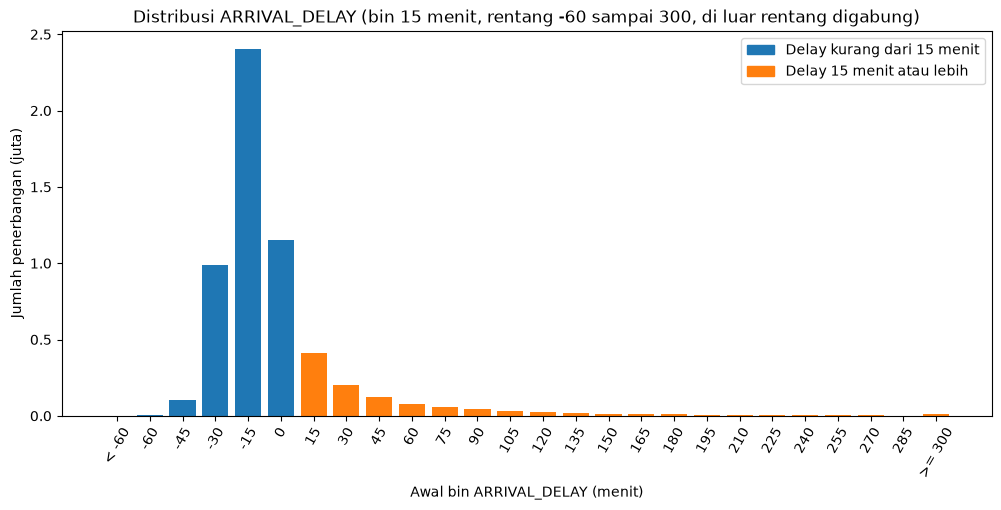

In [60]:
# Grafik 1: histogram ARRIVAL_DELAY (jumlah dalam juta, oranye = delay >= 15 menit)
from matplotlib.patches import Patch

label_bin = []
for awal in hasil_hist["awal_bin"]:
    if awal == -75:
        label_bin.append("< -60")
    elif awal == 300:
        label_bin.append(">= 300")
    else:
        label_bin.append(str(awal))
warna = ["tab:orange" if awal >= 15 else "tab:blue" for awal in hasil_hist["awal_bin"]]
jumlah_juta = hasil_hist["count"] / 1000000

plt.figure(figsize=(12, 5))
plt.bar(label_bin, jumlah_juta, color=warna)
plt.title("Distribusi ARRIVAL_DELAY (bin 15 menit, rentang -60 sampai 300, di luar rentang digabung)")
plt.xlabel("Awal bin ARRIVAL_DELAY (menit)")
plt.ylabel("Jumlah penerbangan (juta)")
plt.xticks(rotation=60)
plt.legend(handles=[Patch(color="tab:blue", label="Delay kurang dari 15 menit"),
                    Patch(color="tab:orange", label="Delay 15 menit atau lebih")],
           loc="upper right")
plt.savefig("../reports/figures/01_distribusi_arrival_delay.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close()

Sumber: `df_hist` (agregasi dari `df_valid`). Mayoritas penerbangan berada di sekitar jadwal atau lebih awal, dengan ekor panjang ke sisi delay besar.

## Grafik 2: Proporsi delay per maskapai

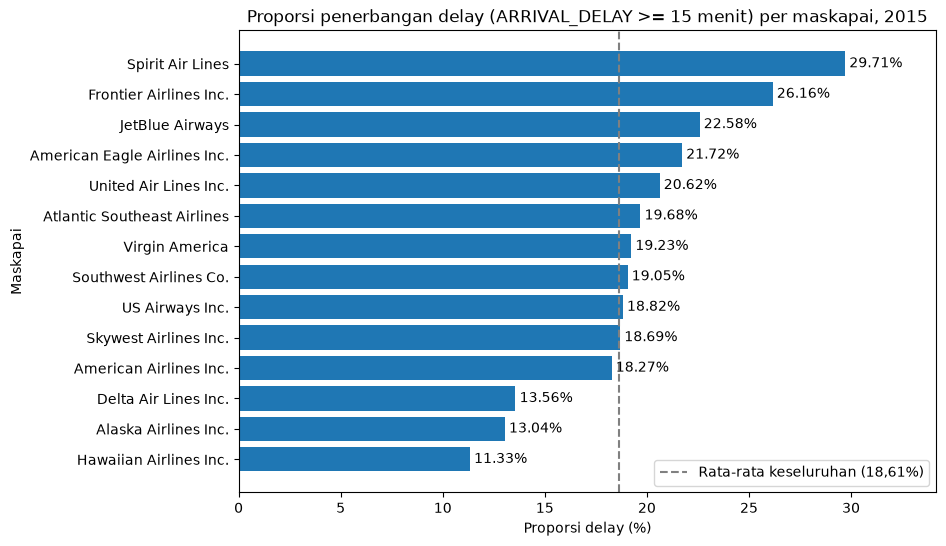

In [61]:
# Grafik 2: proporsi delay per maskapai dari df_maskapai (diurutkan agar yang tertinggi di atas)
hasil_maskapai = df_maskapai.select("NAMA_MASKAPAI", "prop_delay").toPandas()
hasil_maskapai = hasil_maskapai.sort_values("prop_delay", ascending=True)
persen_maskapai = hasil_maskapai["prop_delay"] * 100

plt.figure(figsize=(9, 6))
batang = plt.barh(hasil_maskapai["NAMA_MASKAPAI"], persen_maskapai)
plt.bar_label(batang, fmt="%.2f%%", padding=3)
plt.axvline(rata_delay, color="gray", linestyle="--", label=f"Rata-rata keseluruhan ({teks_rata}%)")
plt.xlim(0, persen_maskapai.max() * 1.15)
plt.title("Proporsi penerbangan delay (ARRIVAL_DELAY >= 15 menit) per maskapai, 2015")
plt.xlabel("Proporsi delay (%)")
plt.ylabel("Maskapai")
plt.legend(loc="lower right")
plt.savefig("../reports/figures/02_delay_per_maskapai.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close()

Sumber: `df_maskapai`. Spirit Air Lines tertinggi (29,71%) dan Hawaiian Airlines terendah (11,33%), selisih 18,38 poin persentase.

## Grafik 3: Proporsi delay per bulan

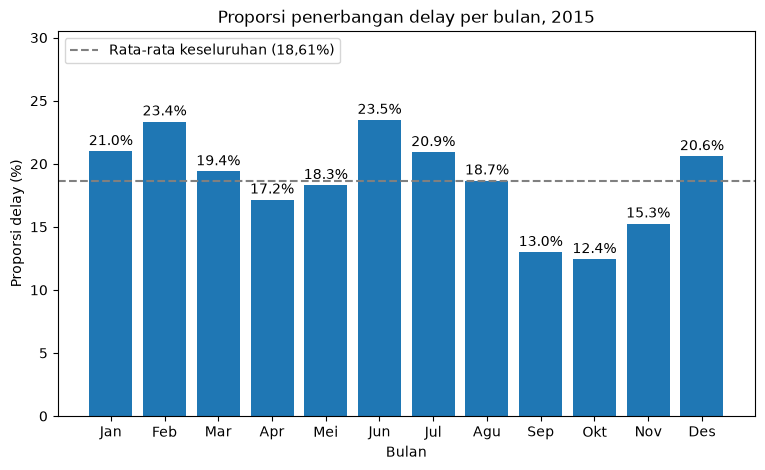

In [62]:
# Grafik 3: proporsi delay per bulan dari df_bulan
hasil_bulan = df_bulan.select("MONTH", "prop_delay").toPandas()
persen_bulan = hasil_bulan["prop_delay"] * 100

plt.figure(figsize=(9, 5))
batang = plt.bar(hasil_bulan["MONTH"], persen_bulan)
plt.bar_label(batang, fmt="%.1f%%", padding=2)
plt.axhline(rata_delay, color="gray", linestyle="--", label=f"Rata-rata keseluruhan ({teks_rata}%)")
plt.ylim(0, persen_bulan.max() * 1.3)
plt.title("Proporsi penerbangan delay per bulan, 2015")
plt.xlabel("Bulan")
plt.ylabel("Proporsi delay (%)")
plt.xticks(range(1, 13), nama_bulan)
plt.legend(loc="upper left")
plt.savefig("../reports/figures/03_delay_per_bulan.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close()

Sumber: `df_bulan`. Proporsi delay tertinggi di bulan 6 (23,48%) dan bulan 2 (23,35%), terendah di bulan 10 (12,44%).

## Grafik 4: Proporsi delay per jam keberangkatan terjadwal

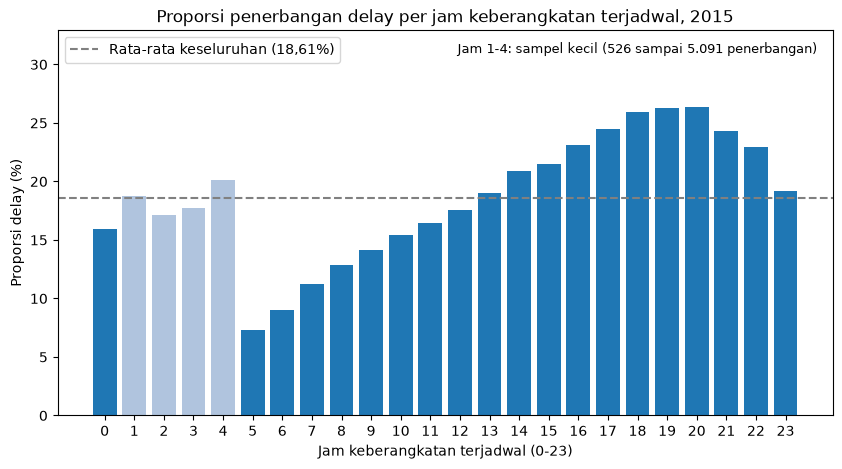

In [63]:
# Grafik 4: proporsi delay per jam jadwal dari df_jam (jam 1-4 diberi warna lebih terang)
hasil_jam = df_jam.select("jam_jadwal", "prop_delay", "total_valid").toPandas()
persen_jam = hasil_jam["prop_delay"] * 100

warna_jam = []
for jam in hasil_jam["jam_jadwal"]:
    if jam >= 1 and jam <= 4:
        warna_jam.append("lightsteelblue")
    else:
        warna_jam.append("tab:blue")

# Rentang jumlah penerbangan pada jam 1-4, diambil dari data grafik
jam_kecil = hasil_jam[(hasil_jam["jam_jadwal"] >= 1) & (hasil_jam["jam_jadwal"] <= 4)]
teks_min = f"{int(jam_kecil['total_valid'].min()):,}".replace(",", ".")
teks_maks = f"{int(jam_kecil['total_valid'].max()):,}".replace(",", ".")

plt.figure(figsize=(10, 5))
plt.bar(hasil_jam["jam_jadwal"], persen_jam, color=warna_jam)
plt.axhline(rata_delay, color="gray", linestyle="--", label=f"Rata-rata keseluruhan ({teks_rata}%)")
plt.ylim(0, persen_jam.max() * 1.25)
plt.text(0.98, 0.97, f"Jam 1-4: sampel kecil ({teks_min} sampai {teks_maks} penerbangan)",
         transform=plt.gca().transAxes, ha="right", va="top", fontsize=9)
plt.title("Proporsi penerbangan delay per jam keberangkatan terjadwal, 2015")
plt.xlabel("Jam keberangkatan terjadwal (0-23)")
plt.ylabel("Proporsi delay (%)")
plt.xticks(range(0, 24))
plt.legend(loc="upper left")
plt.savefig("../reports/figures/04_delay_per_jam.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close()

Sumber: `df_jam`. Proporsi delay terendah pada jam 5 (7,27%), naik hingga puncak pada jam 20 (26,32%). Jam 1 sampai 4 hanya berisi 526 sampai 5.091 penerbangan, jadi proporsinya kurang stabil.

## Grafik 5: Kontribusi penyebab delay

        penyebab  persen_menit
0  Late aircraft         39.84
1        Airline         32.20
2     Air system         22.88
3        Weather          4.95
4       Security          0.13


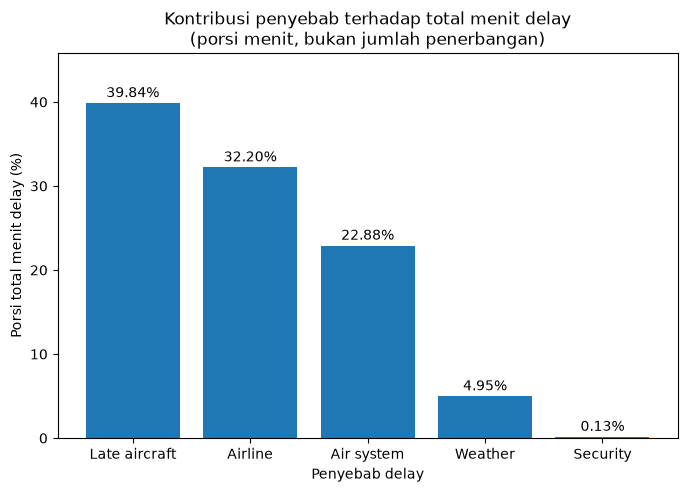

In [64]:
# Grafik 5: porsi MENIT tiap penyebab terhadap total menit delay (dari baris_sebab dan total_menit)
nama_sebab = ["Late aircraft", "Airline", "Air system", "Weather", "Security"]
menit_sebab = [baris_sebab["menit_late_aircraft"], baris_sebab["menit_airline"],
               baris_sebab["menit_air_system"], baris_sebab["menit_weather"],
               baris_sebab["menit_security"]]
persen_sebab = [m * 100 / total_menit for m in menit_sebab]

hasil_sebab = pd.DataFrame({"penyebab": nama_sebab, "persen_menit": persen_sebab}).round(2)
print(hasil_sebab)

plt.figure(figsize=(8, 5))
batang = plt.bar(hasil_sebab["penyebab"], hasil_sebab["persen_menit"])
plt.bar_label(batang, fmt="%.2f%%", padding=2)
plt.ylim(0, hasil_sebab["persen_menit"].max() * 1.15)
plt.title("Kontribusi penyebab terhadap total menit delay\n(porsi menit, bukan jumlah penerbangan)")
plt.xlabel("Penyebab delay")
plt.ylabel("Porsi total menit delay (%)")
plt.savefig("../reports/figures/05_kontribusi_penyebab.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close()

Sumber: `baris_sebab` (dari `df_sebab_total`, penerbangan delay). Late aircraft menyumbang 39,84% menit, airline 32,2%, air system 22,88%, dan security hanya 0,13%.

## Grafik 6: Proporsi delay menurut bulan dan jam jadwal

proporsi tertinggi (bulan, jam): (6, 20) 36.65%
proporsi terendah (bulan, jam) : (9, 5) 4.17%


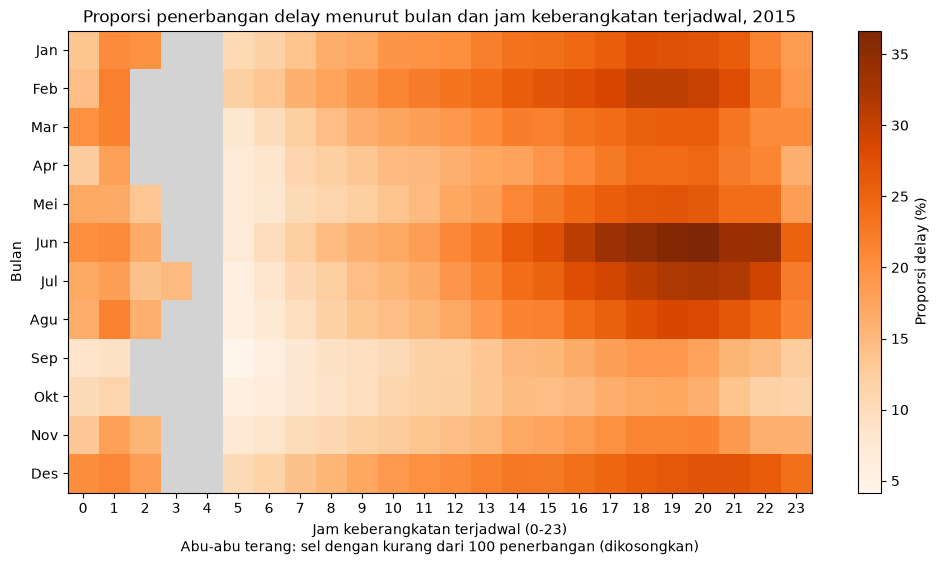

In [65]:
# Grafik 6: heatmap proporsi delay menurut bulan (baris) dan jam jadwal (kolom)
df_bj = (df_valid.groupBy("MONTH", "jam_jadwal")
         .agg(F.count(F.lit(1)).alias("total_valid"),
              F.sum("is_delayed").alias("jumlah_delay"))
         .withColumn("prop_delay", F.col("jumlah_delay") / F.col("total_valid")))
hasil_bj = df_bj.toPandas()

# Pivot ke tabel 12 bulan x 24 jam, sel dengan kurang dari 100 penerbangan dikosongkan (NaN)
tabel_prop = hasil_bj.pivot(index="MONTH", columns="jam_jadwal", values="prop_delay")
tabel_prop = tabel_prop.reindex(index=range(1, 13), columns=range(0, 24)) * 100
tabel_total = hasil_bj.pivot(index="MONTH", columns="jam_jadwal", values="total_valid")
tabel_total = tabel_total.reindex(index=range(1, 13), columns=range(0, 24))
tabel_prop = tabel_prop.where(tabel_total >= 100)

# Warna satu hue bertingkat, sel kosong abu-abu terang
peta_warna = plt.get_cmap("Oranges").copy()
peta_warna.set_bad("lightgray")

# Nilai proporsi delay tertinggi dan terendah di tabel (persen), beserta (bulan, jam)
print("proporsi tertinggi (bulan, jam):", tabel_prop.stack().idxmax(), f"{tabel_prop.stack().max():.2f}%")
print("proporsi terendah (bulan, jam) :", tabel_prop.stack().idxmin(), f"{tabel_prop.stack().min():.2f}%")

plt.figure(figsize=(12, 6))
gambar = plt.imshow(tabel_prop.values, cmap=peta_warna, aspect="auto")
plt.colorbar(gambar, label="Proporsi delay (%)")
plt.xticks(range(24), range(24))
plt.yticks(range(12), nama_bulan)
plt.title("Proporsi penerbangan delay menurut bulan dan jam keberangkatan terjadwal, 2015")
plt.xlabel("Jam keberangkatan terjadwal (0-23)\nAbu-abu terang: sel dengan kurang dari 100 penerbangan (dikosongkan)")
plt.ylabel("Bulan")
plt.savefig("../reports/figures/06_heatmap_bulan_jam.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close()

Sumber: `df_bj` (agregasi dari `df_valid`). Delay menumpuk pada jam 17 sampai 21, paling pekat di bulan Juni, lalu Februari dan Juli. Pagi (jam 5 sampai 8) terang di semua bulan, September dan Oktober terang sepanjang hari. Proporsi tertinggi Juni jam 20 (36,65%) dan terendah September jam 5 (4,17%). Jam dan bulan saling menguatkan, jadi risiko tertinggi adalah penerbangan malam di musim panas atau Februari.

## Grafik 7: Proporsi delay di 10 bandara asal tersibuk

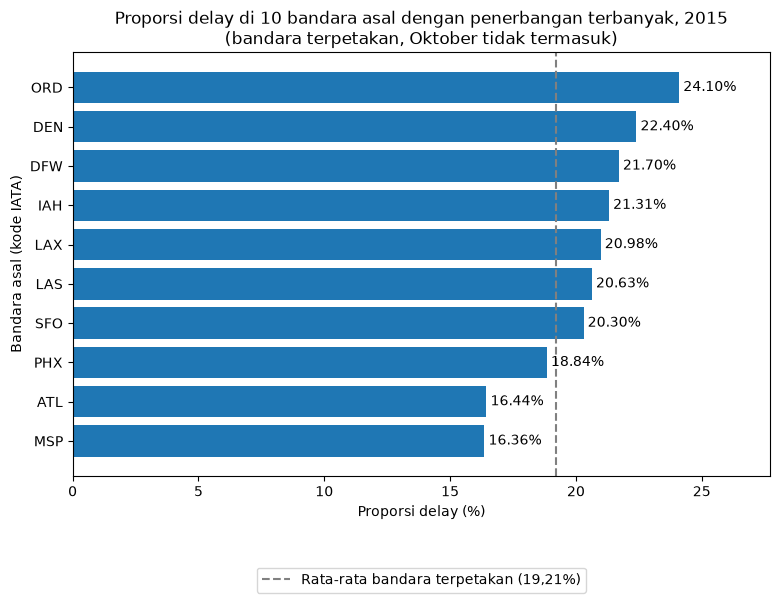

In [66]:
# Grafik 7: 10 bandara asal dengan penerbangan terbanyak dari df_bandara (terpetakan, minimal 1.000 penerbangan)
df_top10 = df_bandara.orderBy(F.desc("total_valid")).limit(10)
hasil_top10 = df_top10.toPandas().sort_values("prop_delay", ascending=True)
persen_top10 = hasil_top10["prop_delay"] * 100

# Rata-rata proporsi delay seluruh baris di df_bandara
baris_rata_bandara = df_bandara.agg(F.sum("jumlah_delay").alias("jumlah_delay"),
                                    F.sum("total_valid").alias("total_valid")).collect()[0]
rata_bandara = baris_rata_bandara["jumlah_delay"] * 100 / baris_rata_bandara["total_valid"]
teks_rata_bandara = f"{rata_bandara:.2f}".replace(".", ",")

plt.figure(figsize=(9, 5.5))
batang = plt.barh(hasil_top10["ORIGIN_AIRPORT"], persen_top10)
plt.bar_label(batang, fmt="%.2f%%", padding=3)
plt.axvline(rata_bandara, color="gray", linestyle="--",
            label=f"Rata-rata bandara terpetakan ({teks_rata_bandara}%)")
plt.xlim(0, persen_top10.max() * 1.15)
plt.title("Proporsi delay di 10 bandara asal dengan penerbangan terbanyak, 2015\n(bandara terpetakan, Oktober tidak termasuk)")
plt.xlabel("Proporsi delay (%)")
plt.ylabel("Bandara asal (kode IATA)")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=1)
plt.savefig("../reports/figures/07_delay_bandara_tersibuk.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close()

Sumber: `df_bandara`. ORD tertinggi (24,10%), disusul DEN (22,40%) dan DFW (21,70%). ATL (16,44%) dan MSP (16,36%) terendah, di bawah rata-rata bandara terpetakan (19,21%). Perbedaan bisa dipengaruhi cuaca, kepadatan, dan campuran maskapai, bukan hanya bandaranya.

## Kesimpulan EDA
- Antarmaskapai: 11,33% (Hawaiian) sampai 29,71% (Spirit).
- Waktu: tertinggi di bulan 6 dan 2, terendah di bulan 10, naik dari jam 5 ke jam 20.
- Menurut menit, penyebab terbesar late aircraft (39,84%) dan airline (32,2%).
- Keterbatasan: bandara dan rute tidak mencakup Oktober (kode numerik), dan semua temuan adalah asosiasi.

# Tahap 4: Preprocessing dan validasi data
Pemeriksaan kualitas dijalankan pada data awal, lalu pembersihan dilakukan berurutan dengan hitungan baris sebelum dan sesudah.

## Pemeriksaan 1: Duplikat
Duplikat diukur dari kombinasi kunci penerbangan: tahun, bulan, hari, maskapai, nomor penerbangan, bandara asal, bandara tujuan, dan jam jadwal.

In [67]:
# Jumlah baris duplikat = total baris - jumlah kombinasi kunci yang unik
kunci = ["YEAR", "MONTH", "DAY", "AIRLINE", "FLIGHT_NUMBER",
         "ORIGIN_AIRPORT", "DESTINATION_AIRPORT", "SCHEDULED_DEPARTURE"]

n_total_cek = df_flights_p.count()
n_unik = df_flights_p.select(kunci).distinct().count()
n_duplikat = n_total_cek - n_unik

print("total baris        :", n_total_cek)
print("kombinasi kunci unik:", n_unik)
print("baris duplikat     :", n_duplikat)

total baris        : 5819079
kombinasi kunci unik: 5819079
baris duplikat     : 0


## Pemeriksaan 2: Nilai kosong
Diperiksa juga apakah null `ARRIVAL_DELAY` sama persis dengan penerbangan batal atau dialihkan.

In [68]:
# Jumlah null per kolom penting + hubungan null ARRIVAL_DELAY dengan batal/dialihkan
df_null = df_flights_p.agg(
    F.sum(F.col("ARRIVAL_DELAY").isNull().cast("int")).alias("null_arrival_delay"),
    F.sum(F.col("DEPARTURE_DELAY").isNull().cast("int")).alias("null_departure_delay"),
    F.sum(F.col("SCHEDULED_TIME").isNull().cast("int")).alias("null_scheduled_time"),
    F.sum(F.col("DISTANCE").isNull().cast("int")).alias("null_distance"),
    F.sum(F.col("TAIL_NUMBER").isNull().cast("int")).alias("null_tail_number"),
    F.sum(F.when((F.col("CANCELLED") == 1) | (F.col("DIVERTED") == 1), 1).otherwise(0)).alias("batal_atau_dialihkan"),
    F.sum(F.when(F.col("ARRIVAL_DELAY").isNull() & (F.col("CANCELLED") == 0) & (F.col("DIVERTED") == 0), 1).otherwise(0)).alias("null_padahal_normal")
)
df_null.show(truncate=False)

baris_null = df_null.collect()[0]
print("null ARRIVAL_DELAY sama dengan batal/dialihkan:", baris_null["null_arrival_delay"] == baris_null["batal_atau_dialihkan"])

+------------------+--------------------+-------------------+-------------+----------------+--------------------+-------------------+
|null_arrival_delay|null_departure_delay|null_scheduled_time|null_distance|null_tail_number|batal_atau_dialihkan|null_padahal_normal|
+------------------+--------------------+-------------------+-------------+----------------+--------------------+-------------------+
|105071            |86153               |6                  |0            |14721           |105071              |0                  |
+------------------+--------------------+-------------------+-------------+----------------+--------------------+-------------------+

null ARRIVAL_DELAY sama dengan batal/dialihkan: True


## Pemeriksaan 3: Rentang nilai
Aturan sah: `MONTH` 1-12, `DAY_OF_WEEK` 1-7, `DISTANCE` > 0, `SCHEDULED_TIME` > 0. Nilai null tidak memenuhi aturan `> 0`, jadi dihitung sebagai tidak lolos.

In [69]:
# Kondisi baris sah (dipakai lagi saat pembersihan)
kondisi_sah = ((F.col("MONTH") >= 1) & (F.col("MONTH") <= 12) &
               (F.col("DAY_OF_WEEK") >= 1) & (F.col("DAY_OF_WEEK") <= 7) &
               (F.col("DISTANCE") > 0) & (F.col("SCHEDULED_TIME") > 0))

# Jumlah pelanggaran per aturan dan jumlah baris yang tidak lolos (null dianggap tidak lolos)
df_rentang = df_flights_p.agg(
    F.sum(F.when((F.col("MONTH") < 1) | (F.col("MONTH") > 12), 1).otherwise(0)).alias("month_di_luar_1_12"),
    F.sum(F.when((F.col("DAY_OF_WEEK") < 1) | (F.col("DAY_OF_WEEK") > 7), 1).otherwise(0)).alias("dow_di_luar_1_7"),
    F.sum(F.when(F.col("DISTANCE") <= 0, 1).otherwise(0)).alias("distance_tidak_positif"),
    F.sum(F.when(F.col("SCHEDULED_TIME") <= 0, 1).otherwise(0)).alias("scheduled_time_tidak_positif"),
    F.sum(F.when(F.coalesce(kondisi_sah, F.lit(False)), 0).otherwise(1)).alias("baris_tidak_lolos")
)
df_rentang.show(truncate=False)
n_langgar = df_rentang.collect()[0]["baris_tidak_lolos"]

+------------------+---------------+----------------------+----------------------------+-----------------+
|month_di_luar_1_12|dow_di_luar_1_7|distance_tidak_positif|scheduled_time_tidak_positif|baris_tidak_lolos|
+------------------+---------------+----------------------+----------------------------+-----------------+
|0                 |0              |0                     |0                           |6                |
+------------------+---------------+----------------------+----------------------------+-----------------+



## Pemeriksaan 4: Konsistensi penyebab delay
Pada penerbangan delay, jumlah lima kolom penyebab diharapkan sama dengan `ARRIVAL_DELAY`.

In [70]:
# Membandingkan jumlah lima penyebab (null dianggap 0) dengan ARRIVAL_DELAY pada penerbangan delay
df_cek_sebab = (df_valid
                .filter(F.col("is_delayed") == 1)
                .withColumn("jumlah_sebab",
                            F.coalesce(F.col("AIR_SYSTEM_DELAY"), F.lit(0)) +
                            F.coalesce(F.col("SECURITY_DELAY"), F.lit(0)) +
                            F.coalesce(F.col("AIRLINE_DELAY"), F.lit(0)) +
                            F.coalesce(F.col("LATE_AIRCRAFT_DELAY"), F.lit(0)) +
                            F.coalesce(F.col("WEATHER_DELAY"), F.lit(0))))
df_sebab_hasil = df_cek_sebab.agg(
    F.count(F.lit(1)).alias("baris_delay"),
    F.sum(F.when(F.col("jumlah_sebab") != F.col("ARRIVAL_DELAY"), 1).otherwise(0)).alias("jumlah_tidak_sama"),
    F.sum(F.when(F.col("AIR_SYSTEM_DELAY").isNull() & F.col("SECURITY_DELAY").isNull() &
                 F.col("AIRLINE_DELAY").isNull() & F.col("LATE_AIRCRAFT_DELAY").isNull() &
                 F.col("WEATHER_DELAY").isNull(), 1).otherwise(0)).alias("semua_penyebab_null")
)
df_sebab_hasil.show(truncate=False)
n_sebab_tidak_sama = df_sebab_hasil.collect()[0]["jumlah_tidak_sama"]

+-----------+-----------------+-------------------+
|baris_delay|jumlah_tidak_sama|semua_penyebab_null|
+-----------+-----------------+-------------------+
|1063439    |0                |0                  |
+-----------+-----------------+-------------------+



## Pemeriksaan 5: Pencilan ARRIVAL_DELAY
Dihitung baris dengan `ARRIVAL_DELAY` di atas 300 menit, beserta berapa di antaranya yang punya penyebab delay tercatat.

In [71]:
# Pencilan: ARRIVAL_DELAY di atas 300 menit pada penerbangan valid
df_pencilan = df_valid.agg(
    F.max("ARRIVAL_DELAY").alias("maksimum"),
    F.sum(F.when(F.col("ARRIVAL_DELAY") > 300, 1).otherwise(0)).alias("di_atas_300"),
    F.sum(F.when((F.col("ARRIVAL_DELAY") > 300) &
                 (F.col("AIR_SYSTEM_DELAY").isNotNull() | F.col("SECURITY_DELAY").isNotNull() |
                  F.col("AIRLINE_DELAY").isNotNull() | F.col("LATE_AIRCRAFT_DELAY").isNotNull() |
                  F.col("WEATHER_DELAY").isNotNull()), 1).otherwise(0)).alias("di_atas_300_ada_penyebab")
)
df_pencilan.show(truncate=False)
n_300 = df_pencilan.collect()[0]["di_atas_300"]

+--------+-----------+------------------------+
|maksimum|di_atas_300|di_atas_300_ada_penyebab|
+--------+-----------+------------------------+
|1971    |11042      |11042                   |
+--------+-----------+------------------------+



**Keputusan:** pencilan dipertahankan karena delay panjang adalah kejadian nyata, bukan galat pengukuran. Target model hanya `ARRIVAL_DELAY >= 15`, jadi nilai ekstrem tidak menggeser hasil.

## Pembersihan berurutan
Batal dan dialihkan dibuang dulu karena tanpa waktu kedatangan, lalu `ARRIVAL_DELAY` null, duplikat, dan pelanggaran rentang.

In [72]:
# Pembersihan berurutan dari df_flights_p, hitung baris sebelum dan sesudah tiap langkah
n0 = df_flights_p.count()

df_s1 = df_flights_p.filter(F.col("CANCELLED") == 0)
n1 = df_s1.count()

df_s2 = df_s1.filter(F.col("DIVERTED") == 0)
n2 = df_s2.count()

df_s3 = df_s2.filter(F.col("ARRIVAL_DELAY").isNotNull())
n3 = df_s3.count()

df_s4 = df_s3.dropDuplicates(kunci)
n4 = df_s4.count()

df_s5 = df_s4.filter(F.coalesce(kondisi_sah, F.lit(False)))
n5 = df_s5.count()

In [73]:
# Tabel ringkas jumlah baris sebelum dan sesudah tiap langkah
hasil_langkah = pd.DataFrame({
    "langkah": ["buang batal", "buang dialihkan", "buang ARRIVAL_DELAY null",
                "hapus duplikat", "buang pelanggaran rentang"],
    "sebelum": [n0, n1, n2, n3, n4],
    "sesudah": [n1, n2, n3, n4, n5]})
hasil_langkah["dibuang"] = hasil_langkah["sebelum"] - hasil_langkah["sesudah"]
print(hasil_langkah.to_string(index=False))

                  langkah  sebelum  sesudah  dibuang
              buang batal  5819079  5729195    89884
          buang dialihkan  5729195  5714008    15187
 buang ARRIVAL_DELAY null  5714008  5714008        0
           hapus duplikat  5714008  5714008        0
buang pelanggaran rentang  5714008  5714008        0


## Kolom turunan dan penanda kode bandara
`is_delayed` dan `jam_jadwal` ditambahkan. Baris Oktober (kode bandara numerik) dipertahankan untuk analisis maskapai, bulan, dan model, tetapi tidak untuk bandara dan rute (ditandai `asal_terpetakan` dan `tujuan_terpetakan`).

In [74]:
# Daftar kode bandara yang ada di airports.csv (hanya 322 baris, aman di-collect)
kode_bandara = [baris["IATA_CODE"] for baris in df_airports.select("IATA_CODE").collect()]

# df_bersih: kolom turunan + penanda kode bandara terpetakan
df_bersih = (df_s5
             .withColumn("is_delayed", F.when(F.col("ARRIVAL_DELAY") >= 15, 1).otherwise(0))
             .withColumn("jam_jadwal", F.substring("SCHEDULED_DEPARTURE", 1, 2).cast("int"))
             .withColumn("asal_terpetakan", F.coalesce(F.col("ORIGIN_AIRPORT").isin(kode_bandara), F.lit(False)))
             .withColumn("tujuan_terpetakan", F.coalesce(F.col("DESTINATION_AIRPORT").isin(kode_bandara), F.lit(False))))

In [75]:
# Jumlah baris menurut status keterpetaan kode bandara
df_bersih.groupBy("asal_terpetakan", "tujuan_terpetakan").count().show()

+---------------+-----------------+-------+
|asal_terpetakan|tujuan_terpetakan|  count|
+---------------+-----------------+-------+
|           true|             true|5231130|
|          false|            false| 482878|
+---------------+-----------------+-------+



## Kolom untuk model
Hanya kolom yang diketahui sebelum berangkat yang dipakai. `DEPARTURE_DELAY`, `TAXI_OUT`, `ELAPSED_TIME`, `AIR_TIME`, kolom penyebab delay, dan `ARRIVAL_DELAY` dikeluarkan karena kebocoran.

In [76]:
# df_model: fitur pra-keberangkatan + target is_delayed
df_model = df_bersih.select("MONTH", "DAY_OF_WEEK", "jam_jadwal", "AIRLINE",
                            "ORIGIN_AIRPORT", "DESTINATION_AIRPORT",
                            "DISTANCE", "SCHEDULED_TIME", "is_delayed")
df_model.printSchema()

root
 |-- MONTH: integer (nullable = true)
 |-- DAY_OF_WEEK: integer (nullable = true)
 |-- jam_jadwal: integer (nullable = true)
 |-- AIRLINE: string (nullable = true)
 |-- ORIGIN_AIRPORT: string (nullable = true)
 |-- DESTINATION_AIRPORT: string (nullable = true)
 |-- DISTANCE: integer (nullable = true)
 |-- SCHEDULED_TIME: integer (nullable = true)
 |-- is_delayed: integer (nullable = false)



## Menyimpan data bersih

In [77]:
# Menyimpan df_bersih (semua kolom) ke Parquet, lalu membaca ulang untuk verifikasi jumlah baris
df_bersih.write.mode("overwrite").parquet("../data/processed/flights_clean")

df_cek_bersih = spark.read.parquet("../data/processed/flights_clean")
print("baris df_bersih (dari langkah terakhir):", n5)
print("baris Parquet flights_clean           :", df_cek_bersih.count())

baris df_bersih (dari langkah terakhir): 5714008
baris Parquet flights_clean           : 5714008


In [78]:
# Ringkasan angka Tahap 4
print("baris awal                     :", n0)
print("baris akhir (df_bersih)        :", n5)
print("baris duplikat                 :", n_duplikat)
print("baris tidak lolos rentang      :", n_langgar)
print("penyebab tidak sama dgn delay  :", n_sebab_tidak_sama)
print("ARRIVAL_DELAY di atas 300 menit:", n_300)

baris awal                     : 5819079
baris akhir (df_bersih)        : 5714008
baris duplikat                 : 0
baris tidak lolos rentang      : 6
penyebab tidak sama dgn delay  : 0
ARRIVAL_DELAY di atas 300 menit: 11042


## Ringkasan Tahap 4
- Pembersihan: 5.819.079 menjadi 5.714.008 baris, dibuang 105.071 (89.884 batal dan 15.187 dialihkan), sedangkan null ARRIVAL_DELAY, duplikat, dan pelanggaran rentang masing-masing 0 baris.
- Null ARRIVAL_DELAY sama persis dengan batal atau dialihkan (105.071). Jumlah lima penyebab selalu sama dengan ARRIVAL_DELAY pada 1.063.439 baris delay.
- Pencilan: 11.042 baris di atas 300 menit semuanya punya penyebab tercatat, jadi dipertahankan.
- Baris Oktober (482.878) dipertahankan dengan penanda keterpetaan bandara.

# Tahap 5: Baseline MLlib
`LogisticRegression` memprediksi `is_delayed` dari fitur jadwal, rute, dan maskapai, dengan pembagian acak seed 42 pada seluruh data.

## Data model
Data dibaca dari Parquet `flights_clean` (isi sama dengan `df_bersih`) agar urutan baris tetap. Kode bandara tidak terpetakan diganti "LAINNYA" karena kode numerik Oktober memecah satu bandara menjadi dua kategori.

In [79]:
# Membaca data bersih dari Parquet (isinya sama dengan df_bersih)
df_bersih_p = spark.read.parquet("../data/processed/flights_clean")

In [80]:
# Menyiapkan data model: kode bandara tidak terpetakan menjadi "LAINNYA",
# kolom waktu di-cast ke string agar diperlakukan sebagai kategori
df_ml = (df_bersih_p
         .withColumn("ORIGIN_AIRPORT", F.when(F.col("asal_terpetakan"), F.col("ORIGIN_AIRPORT")).otherwise("LAINNYA"))
         .withColumn("DESTINATION_AIRPORT", F.when(F.col("tujuan_terpetakan"), F.col("DESTINATION_AIRPORT")).otherwise("LAINNYA"))
         .withColumn("MONTH", F.col("MONTH").cast("string"))
         .withColumn("DAY_OF_WEEK", F.col("DAY_OF_WEEK").cast("string"))
         .withColumn("jam_jadwal", F.col("jam_jadwal").cast("string"))
         .select("MONTH", "DAY_OF_WEEK", "jam_jadwal", "AIRLINE", "ORIGIN_AIRPORT",
                 "DESTINATION_AIRPORT", "DISTANCE", "SCHEDULED_TIME", "is_delayed"))

baris_ml = df_ml.agg(F.count(F.lit(1)).alias("jumlah"), F.mean("is_delayed").alias("prop_delay")).collect()[0]
print("jumlah baris data model :", baris_ml["jumlah"])
print("proporsi is_delayed     :", baris_ml["prop_delay"])

jumlah baris data model : 5714008
proporsi is_delayed     : 0.18611086998828144


## Pembagian data latih dan uji
80% latih dan 20% uji, acak dengan seed 42, seluruh data.

In [81]:
# Membagi data secara acak
df_latih, df_uji = df_ml.randomSplit([0.8, 0.2], seed=42)

baris_latih = df_latih.agg(F.count(F.lit(1)).alias("jumlah"), F.mean("is_delayed").alias("prop_delay")).collect()[0]
baris_uji = df_uji.agg(F.count(F.lit(1)).alias("jumlah"), F.mean("is_delayed").alias("prop_delay")).collect()[0]
print("latih -> baris:", baris_latih["jumlah"], "| proporsi is_delayed:", baris_latih["prop_delay"])
print("uji   -> baris:", baris_uji["jumlah"], "| proporsi is_delayed:", baris_uji["prop_delay"])

latih -> baris: 4571196 | proporsi is_delayed: 0.18615653321362724
uji   -> baris: 1142812 | proporsi is_delayed: 0.18592821916465702


## Pembanding naif
Prediksi "tidak delay" untuk semua baris uji.

In [82]:
# Akurasi pembanding naif pada df_uji (semua diprediksi is_delayed = 0)
akurasi_naif = df_uji.agg(F.mean(F.when(F.col("is_delayed") == 0, 1).otherwise(0))).collect()[0][0]
print("akurasi pembanding naif:", akurasi_naif)

akurasi pembanding naif: 0.814071780835343


## Pipeline dan model
Kelas delay lebih sedikit, jadi `LogisticRegression` memakai bobot kelas dari data latih. Evaluasi pada data uji tanpa bobot.

In [83]:
# Mengimpor komponen MLlib
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.evaluation import BinaryClassificationEvaluator

In [84]:
# Bobot kelas dari data latih: jumlah baris / (2 x jumlah baris kelas), hanya ditambahkan ke df_latih
n_latih = df_latih.count()
n_delay = df_latih.filter(F.col("is_delayed") == 1).count()
n_tepat = n_latih - n_delay
bobot_delay = n_latih / (2 * n_delay)
bobot_tepat = n_latih / (2 * n_tepat)
print("bobot kelas delay :", bobot_delay)
print("bobot kelas tepat :", bobot_tepat)

df_latih = df_latih.withColumn("bobot", F.when(F.col("is_delayed") == 1, bobot_delay).otherwise(bobot_tepat))

bobot kelas delay : 2.685911643112821
bobot kelas tepat : 0.6143687581278402


In [85]:
# Tahap pipeline: StringIndexer + OneHotEncoder untuk kolom kategori,
# VectorAssembler + StandardScaler untuk DISTANCE dan SCHEDULED_TIME
kolom_kategori = ["AIRLINE", "ORIGIN_AIRPORT", "DESTINATION_AIRPORT", "MONTH", "DAY_OF_WEEK", "jam_jadwal"]

tahap_indexer = []
for nama in kolom_kategori:
    tahap_indexer.append(StringIndexer(inputCol=nama, outputCol=nama + "_idx", handleInvalid="keep"))

encoder = OneHotEncoder(inputCols=[nama + "_idx" for nama in kolom_kategori],
                        outputCols=[nama + "_ohe" for nama in kolom_kategori],
                        handleInvalid="keep")

assembler_angka = VectorAssembler(inputCols=["DISTANCE", "SCHEDULED_TIME"], outputCol="angka_vec")
scaler = StandardScaler(inputCol="angka_vec", outputCol="angka_skala", withMean=True, withStd=True)

assembler_akhir = VectorAssembler(inputCols=[nama + "_ohe" for nama in kolom_kategori] + ["angka_skala"],
                                  outputCol="features")

model_lr = LogisticRegression(featuresCol="features", labelCol="is_delayed", weightCol="bobot", maxIter=20)

pipeline = Pipeline(stages=tahap_indexer + [encoder, assembler_angka, scaler, assembler_akhir, model_lr])

In [86]:
# Melatih pipeline hanya pada data latih
model_pipeline = pipeline.fit(df_latih)

## Evaluasi pada data uji
Evaluasi tanpa bobot. Precision, recall, dan F1 dihitung untuk kelas delay pada threshold 0,5.

In [87]:
# Prediksi data uji dan AUC
df_prediksi = model_pipeline.transform(df_uji)

evaluator_auc = BinaryClassificationEvaluator(labelCol="is_delayed", rawPredictionCol="rawPrediction",
                                              metricName="areaUnderROC")
auc = evaluator_auc.evaluate(df_prediksi)
print("AUC:", auc)

AUC: 0.654893404732351


In [88]:
# Matriks konfusi dari hitungan label dan prediksi
hasil_konfusi = df_prediksi.groupBy("is_delayed", "prediction").count().collect()

tp = 0
fp = 0
fn = 0
tn = 0
for baris in hasil_konfusi:
    if baris["is_delayed"] == 1 and baris["prediction"] == 1.0:
        tp = baris["count"]
    elif baris["is_delayed"] == 0 and baris["prediction"] == 1.0:
        fp = baris["count"]
    elif baris["is_delayed"] == 1 and baris["prediction"] == 0.0:
        fn = baris["count"]
    else:
        tn = baris["count"]

tabel_konfusi = pd.DataFrame([[tn, fp], [fn, tp]],
                             index=["aktual tepat waktu", "aktual delay"],
                             columns=["prediksi tepat waktu", "prediksi delay"])
print(tabel_konfusi)

                    prediksi tepat waktu  prediksi delay
aktual tepat waktu                544888          385443
aktual delay                       76376          136105


In [89]:
# Precision, recall, F1 kelas delay, dan akurasi dibandingkan dengan pembanding naif
precision = tp / (tp + fp)
recall = tp / (tp + fn)
f1 = 2 * precision * recall / (precision + recall)
akurasi_model = (tp + tn) / (tp + tn + fp + fn)

print("precision (delay):", precision)
print("recall (delay)   :", recall)
print("F1 (delay)       :", f1)
print("akurasi model    :", akurasi_model)
print("akurasi naif     :", akurasi_naif)

precision (delay): 0.2609635163014718
recall (delay)   : 0.6405513904772662
F1 (delay)       : 0.3708436587655256
akurasi model    : 0.5958924127503037
akurasi naif     : 0.814071780835343


Akurasi saja menyesatkan karena kelas tidak seimbang, jadi AUC, precision, recall, dan F1 kelas delay dipakai untuk menilai model.

## Hyperparameter tuning
Grid search atas `regParam` dan `elasticNetParam` dengan validasi 20% dari data latih. Data uji tidak dipakai untuk memilih parameter, hanya untuk evaluasi akhir.

In [90]:
# Grid search regParam dan elasticNetParam dengan TrainValidationSplit (80% latih, 20% validasi, seed 42), hanya memakai df_latih
from pyspark.ml.tuning import ParamGridBuilder, TrainValidationSplit

# regParam 0.0 tidak dimasukkan karena pada regParam 0 elasticNetParam tidak berpengaruh,
# dan baseline (regParam 0) sudah ada sebagai pembanding
grid = (ParamGridBuilder()
        .addGrid(model_lr.regParam, [0.001, 0.01, 0.1])
        .addGrid(model_lr.elasticNetParam, [0.0, 0.5])
        .build())
print("jumlah kombinasi:", len(grid))

evaluator_tuning = BinaryClassificationEvaluator(labelCol="is_delayed", metricName="areaUnderROC")

tuning = TrainValidationSplit(estimator=pipeline,
                              estimatorParamMaps=grid,
                              evaluator=evaluator_tuning,
                              trainRatio=0.8,
                              seed=42)
model_tuning = tuning.fit(df_latih)

# AUC validasi untuk tiap kombinasi
for i in range(len(grid)):
    reg = grid[i][model_lr.regParam]
    en = grid[i][model_lr.elasticNetParam]
    print("regParam", reg, "elasticNetParam", en, "-> AUC validasi:", model_tuning.validationMetrics[i])

# Kombinasi terbaik dari model terbaik
model_terbaik = model_tuning.bestModel
print("regParam terbaik        :", model_terbaik.stages[-1].getRegParam())
print("elasticNetParam terbaik :", model_terbaik.stages[-1].getElasticNetParam())

jumlah kombinasi: 6


regParam 0.001 elasticNetParam 0.0 -> AUC validasi: 0.6537522059141341
regParam 0.001 elasticNetParam 0.5 -> AUC validasi: 0.6525007050347654
regParam 0.01 elasticNetParam 0.0 -> AUC validasi: 0.653239663809039
regParam 0.01 elasticNetParam 0.5 -> AUC validasi: 0.6439665676352898
regParam 0.1 elasticNetParam 0.0 -> AUC validasi: 0.6521897778197351
regParam 0.1 elasticNetParam 0.5 -> AUC validasi: 0.5
regParam terbaik        : 0.001
elasticNetParam terbaik : 0.0


Kombinasi terbaik dipilih dari AUC validasi, bukan dari data uji. Baseline (regParam 0) tetap menjadi pembanding.

In [91]:
# Prediksi untuk empat pasangan model dan data (evaluasi tanpa bobot)
dict_prediksi = {
    "baseline latih": model_pipeline.transform(df_latih),
    "baseline uji": model_pipeline.transform(df_uji),
    "tuning latih": model_terbaik.transform(df_latih),
    "tuning uji": model_terbaik.transform(df_uji),
}

# Hitung AUC, matriks konfusi, precision, recall, F1 (kelas delay, threshold 0,5), dan akurasi
dict_konfusi = {}
hasil_ringkas = []
for nama in dict_prediksi:
    df_p = dict_prediksi[nama]
    auc_k = evaluator_auc.evaluate(df_p)

    hasil_k = df_p.groupBy("is_delayed", "prediction").count().collect()
    tp_k = 0
    fp_k = 0
    fn_k = 0
    tn_k = 0
    for baris in hasil_k:
        if baris["is_delayed"] == 1 and baris["prediction"] == 1.0:
            tp_k = baris["count"]
        elif baris["is_delayed"] == 0 and baris["prediction"] == 1.0:
            fp_k = baris["count"]
        elif baris["is_delayed"] == 1 and baris["prediction"] == 0.0:
            fn_k = baris["count"]
        else:
            tn_k = baris["count"]

    precision_k = tp_k / (tp_k + fp_k)
    recall_k = tp_k / (tp_k + fn_k)
    f1_k = 2 * precision_k * recall_k / (precision_k + recall_k)
    akurasi_k = (tp_k + tn_k) / (tp_k + tn_k + fp_k + fn_k)

    dict_konfusi[nama] = pd.DataFrame([[tn_k, fp_k], [fn_k, tp_k]],
                                      index=["aktual tepat waktu", "aktual delay"],
                                      columns=["prediksi tepat waktu", "prediksi delay"])
    hasil_ringkas.append([nama, auc_k, precision_k, recall_k, f1_k, akurasi_k])

In [92]:
# Mencetak empat matriks konfusi dan tabel ringkasan
for nama in dict_konfusi:
    print(nama)
    print(dict_konfusi[nama])
    print()

tabel_ringkasan = pd.DataFrame(hasil_ringkas,
                               columns=["model_data", "AUC", "precision", "recall", "F1", "akurasi"])
print(tabel_ringkasan.round(4).to_string(index=False))
print()
print("catatan: akurasi pembanding naif pada data uji =", akurasi_naif)

baseline latih
                    prediksi tepat waktu  prediksi delay
aktual tepat waktu               2178520         1541718
aktual delay                      305428          545530

baseline uji
                    prediksi tepat waktu  prediksi delay
aktual tepat waktu                544888          385443
aktual delay                       76376          136105

tuning latih
                    prediksi tepat waktu  prediksi delay
aktual tepat waktu               2178379         1541859
aktual delay                      305341          545617

tuning uji
                    prediksi tepat waktu  prediksi delay
aktual tepat waktu                544856          385475
aktual delay                       76344          136137

    model_data    AUC  precision  recall     F1  akurasi
baseline latih 0.6549     0.2614  0.6411 0.3713   0.5959
  baseline uji 0.6549     0.2610  0.6406 0.3708   0.5959
  tuning latih 0.6547     0.2614  0.6412 0.3714   0.5959
    tuning uji 0.6547     0.2610

## Grafik 8: Matriks konfusi data uji

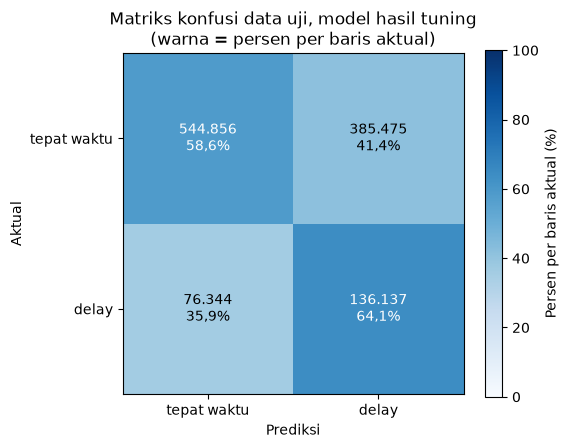

In [93]:
# Grafik 8: matriks konfusi data uji model hasil tuning, warna = persen per baris aktual
konfusi_uji = dict_konfusi["tuning uji"]
persen_baris = konfusi_uji.div(konfusi_uji.sum(axis=1), axis=0) * 100

plt.figure(figsize=(5.5, 4.5))
gambar = plt.imshow(persen_baris.values, cmap="Blues", vmin=0, vmax=100)
plt.colorbar(gambar, label="Persen per baris aktual (%)")

# Teks jumlah baris dan persen di tiap sel
for i in range(2):
    for j in range(2):
        jumlah = f"{int(konfusi_uji.iloc[i, j]):,}".replace(",", ".")
        persen = f"{persen_baris.iloc[i, j]:.1f}".replace(".", ",")
        warna_teks = "white" if persen_baris.iloc[i, j] > 50 else "black"
        plt.text(j, i, jumlah + "\n" + persen + "%", ha="center", va="center", color=warna_teks)

plt.xticks([0, 1], ["tepat waktu", "delay"])
plt.yticks([0, 1], ["tepat waktu", "delay"])
plt.title("Matriks konfusi data uji, model hasil tuning\n(warna = persen per baris aktual)")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.savefig("../reports/figures/08_matriks_konfusi_uji.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close()

Sumber: `dict_konfusi["tuning uji"]`. Model menangkap 64,1% penerbangan yang benar-benar delay (136.137 dari 212.481), tetapi 41,4% penerbangan tepat waktu salah ditandai delay (385.475). Ini akibat bobot kelas yang memprioritaskan recall.

## Grafik 9: Proporsi delay sebenarnya per desil skor model

26/11/02 17:24:43 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/02 17:24:43 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/02 17:24:49 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/02 17:24:49 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


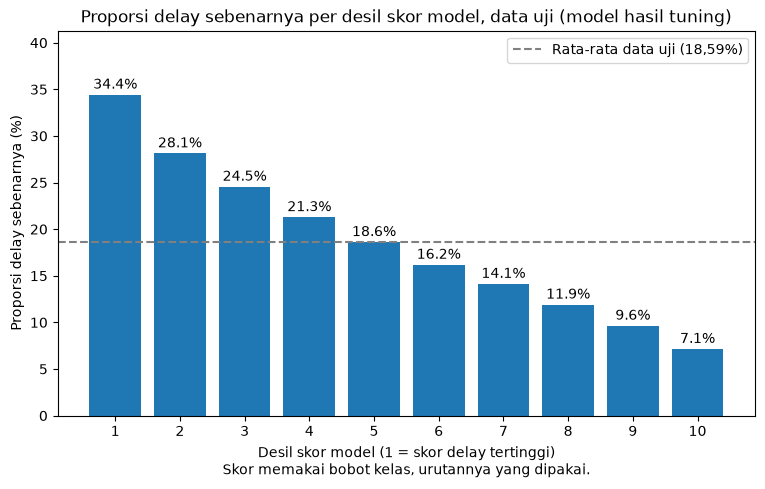

In [94]:
# Grafik 9: proporsi delay sebenarnya per desil skor model (data uji, model hasil tuning)
from pyspark.ml.functions import vector_to_array

# Skor = probabilitas kelas delay (indeks 1)
df_skor = dict_prediksi["tuning uji"].select(
    "is_delayed",
    vector_to_array("probability")[1].alias("skor_delay"))

# Desil 1 = skor delay tertinggi
jendela_skor = Window.orderBy(F.desc("skor_delay"))
df_desil = df_skor.withColumn("desil", F.ntile(10).over(jendela_skor))

# Agregasi per desil di Spark, hanya 10 baris yang diubah ke pandas
df_lift = (df_desil.groupBy("desil")
           .agg(F.count(F.lit(1)).alias("jumlah_baris"),
                F.mean("is_delayed").alias("prop_delay"))
           .orderBy("desil"))
hasil_lift = df_lift.toPandas()
persen_lift = hasil_lift["prop_delay"] * 100

# Proporsi delay seluruh data uji, dihitung dari 10 baris agregasi
rata_uji = (hasil_lift["jumlah_baris"] * hasil_lift["prop_delay"]).sum() * 100 / hasil_lift["jumlah_baris"].sum()
teks_rata_uji = f"{rata_uji:.2f}".replace(".", ",")

plt.figure(figsize=(9, 5))
batang = plt.bar(hasil_lift["desil"], persen_lift)
plt.bar_label(batang, fmt="%.1f%%", padding=2)
plt.axhline(rata_uji, color="gray", linestyle="--", label=f"Rata-rata data uji ({teks_rata_uji}%)")
plt.ylim(0, persen_lift.max() * 1.2)
plt.title("Proporsi delay sebenarnya per desil skor model, data uji (model hasil tuning)")
plt.xlabel("Desil skor model (1 = skor delay tertinggi)\nSkor memakai bobot kelas, urutannya yang dipakai.")
plt.ylabel("Proporsi delay sebenarnya (%)")
plt.xticks(range(1, 11))
plt.legend(loc="upper right")
plt.savefig("../reports/figures/09_lift_per_desil.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close()

Sumber: `df_lift` (dari `dict_prediksi["tuning uji"]`). Proporsi delay sebenarnya turun konsisten dari 34,4% di desil 1 ke 7,1% di desil 10, sedangkan rata-rata data uji 18,59%. Desil 1 sekitar 1,9 kali rata-rata. Model lemah sebagai penebak ya atau tidak, tetapi cukup berguna untuk mengurutkan risiko.

Overfit: AUC latih dan uji sama (baseline 0,6549 dan 0,6549, tuning 0,6547 dan 0,6547), jadi tidak ada tanda overfit.

Tuning: kombinasi terbaik regParam 0,001 dan elasticNetParam 0,0 (AUC validasi 0,6538). AUC uji tuning 0,6547 dan baseline 0,6549, selisih 0,0002 terlalu kecil untuk dianggap beda. Regularisasi kuat justru merugikan (AUC validasi 0,5 pada regParam 0,1 dan elasticNetParam 0,5).

## Keterbatasan model
Fitur hanya jadwal, rute, dan maskapai, tanpa cuaca atau kondisi riil. Baris Oktober memiliki kategori bandara "LAINNYA" karena kodenya numerik. Hasilnya asosiasi, bukan sebab-akibat. Ruang pencarian hyperparameter kecil (6 kombinasi) dan maxIter tetap 20.

**Interpretasi:** Model hanya sedikit lebih baik dari tebakan acak (AUC uji 0,6549 untuk baseline dan 0,6547 setelah tuning). Dengan bobot kelas, model menangkap 64,06% delay sebenarnya (recall) tetapi hanya 26,10% tebakan delay yang benar (precision), dengan F1 0,3708. Akurasi 0,5959 lebih rendah dari pembanding naif (0,8141) karena bobot kelas, bukan karena model rusak. Tuning tidak menaikkan hasil, jadi batasnya ada di informasi fitur, bukan di pengaturan model.

# Tahap 6: Temuan, keterbatasan, dan rekomendasi

## Temuan
- Maskapai: proporsi delay tertinggi Spirit (29,71%), terendah Hawaiian (11,33%), selisih 18,38 poin persentase (Grafik 2).
- Bulan: tertinggi bulan 6 (23,48%) dan bulan 2 (23,35%), terendah bulan 10 (12,44%) (Grafik 3).
- Jam jadwal: terendah jam 5 (7,27%), naik hingga puncak jam 20 (26,32%) (Grafik 4).
- Penyebab: late aircraft 39,84% menit delay, airline 32,2%, air system 22,88%, weather 4,95%, security 0,13% (Grafik 5).

## Keterbatasan
- Kode bandara bulan Oktober numerik (482.878 baris valid), jadi analisis bandara dan rute tidak mencakup Oktober.
- Data hanya tahun 2015 dan semua temuan adalah asosiasi, bukan sebab-akibat. Perbedaan antarmaskapai bisa dipengaruhi campuran rute dan bandara.
- Model hanya memakai fitur jadwal, rute, dan maskapai, tanpa cuaca atau rotasi pesawat (performa model: lihat Tahap 5).
- Pembagian data latih dan uji acak per baris, bukan berdasarkan waktu.

## Rekomendasi
- Bagi penumpang: penerbangan jam 5 sampai 8 punya proporsi delay terendah (7,27% sampai 12,90%) dibanding sore dan malam.
- Bagi maskapai atau operator: delay terbesar menurut menit adalah late aircraft, jadi jadwal perputaran pesawat dan waktu cadangan layak dievaluasi.
- Untuk analisis lanjutan: tambahkan data cuaca dan riwayat penerbangan sebelumnya pada pesawat yang sama (`TAIL_NUMBER`) sebagai fitur.